# TP EDA Python — M1 Big Data Analytics (IHEC Carthage, 2026/2027)
**Parties 1 à 9 — Q1 à Q52** | Fichiers : `sales.csv`, `products.csv`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


# Partie 1 — Chargement et exploration initiale

## Q1 — Chargement, premières et dernières lignes

In [2]:
sales_raw = pd.read_csv('data/sales.csv')
products = pd.read_csv('data/products.csv')

print('sales — 5 premières lignes'); display(sales_raw.head())
print('sales — 5 dernières lignes'); display(sales_raw.tail())
print('products — 5 premières lignes'); display(products.head())
print('products — 5 dernières lignes'); display(products.tail())

sales — 5 premières lignes


,index,OrderID,Date,OrderTime,Region,ville,StoreID,Channel,customer,ProductID,Units,UnitPrice,disc,prom,PaymentType
0,206,1001,1.743120e+18,15:08:00,South West,Kebili,10,Retail,508,209,4,28.72,0.0,False,Cash
1,731,1002,1.762730e+18,51:52.8,Centre East,Monastir,11,Online,506,203,8,33.77,0.1,True,Credit
2,268,1003,1.750460e+18,19:43:24,Centre East,Mahdia,15,Online,502,202,7,31.08,0.0,False,Credit
3,748,1004,1.745970e+18,NaN,Centre West,Kasserine,15,Online,506,208,15,30.39,0.0,False,Credit
4,449,1005,1.743720e+18,41:04.8,Centre East,Sousse,11,Online,501,209,15,32.31,0.0,False,Credit


sales — 5 dernières lignes


,index,OrderID,Date,OrderTime,Region,ville,StoreID,Channel,customer,ProductID,Units,UnitPrice,disc,prom,PaymentType
811,795,1778,1.713050e+18,NaN,South East,Medenine,11,Retail,506,209,4,37.52,0.25,False,Credit
812,627,1501,1.733180e+18,15:15:24,North East,Tunis,13,Retail,506,200,8,45.29,0.25,True,Credit
813,21,1006,1.725750e+18,13:33.6,North East,Manouba,15,Retail,507,205,12,36.24,0.20,False,Credit
814,640,1724,1.734310e+18,00:07.2,South East,Sfax,14,NaN,506,209,7,27.45,0.30,False,Credit
815,652,1666,1.722120e+18,24:04.8,Centre West,Kasserine,10,Online,503,203,6,14.46,0.00,False,Cash


products — 5 premières lignes


,ProductID,ProductName,Category
0,205,E-book,Digital Products
1,203,iphone,Electronics
2,209,cleaning products,Household
3,206,Online course,Digital Products
4,202,Computer,Electronics


products — 5 dernières lignes


,ProductID,ProductName,Category
5,207,Handbag,Accessories
6,204,blender,Electronics
7,201,toothpaste,Personal Care
8,200,Shampoo,Personal Care
9,208,watch,Accessories


## Q2 — Dimensions, colonnes, types, mémoire

In [3]:
for name, d in [('sales', sales_raw), ('products', products)]:
    print(f'===== {name} =====')
    print('Dimension :', d.shape)
    print('Colonnes  :', list(d.columns))
    print(d.dtypes.to_string())
    print(f'Mémoire   : {d.memory_usage(deep=True).sum() / 1024:.1f} Ko\n')

print('Transactions (lignes de sales) :', len(sales_raw), '| OrderID distincts :', sales_raw.OrderID.nunique())
print('Produits dans le référentiel   :', len(products), '| ProductID distincts dans sales :', sales_raw.ProductID.nunique())

===== sales =====
Dimension : (816, 15)
Colonnes  : ['index', 'OrderID', 'Date', 'OrderTime', 'Region', 'ville', 'StoreID', 'Channel', 'customer', 'ProductID', 'Units', 'UnitPrice', 'disc', 'prom', 'PaymentType']
index            int64
OrderID          int64
Date           float64
OrderTime          str
Region             str
ville              str
StoreID          int64
Channel            str
customer         int64
ProductID        int64
Units            int64
UnitPrice      float64
disc           float64
prom              bool
PaymentType        str
Mémoire   : 275.9 Ko

===== products =====
Dimension : (10, 3)
Colonnes  : ['ProductID', 'ProductName', 'Category']
ProductID      int64
ProductName      str
Category         str
Mémoire   : 1.4 Ko

Transactions (lignes de sales) : 816 | OrderID distincts : 800
Produits dans le référentiel   : 10 | ProductID distincts dans sales : 7


**Lecture** : `sales` contient 816 lignes (transactions brutes, dont 16 répétées → 800 `OrderID` distincts) et 15 colonnes ; `products` contient 10 produits et 3 colonnes. Les deux fichiers sont légers.

## Q3 — Dictionnaire de données

In [4]:
dico = [
    ('index', 'Numéro de ligne / index technique issu de l\'export', 'Technique (à écarter)', 'Oui'),
    ('OrderID', 'Identifiant de la commande', 'Clé de transaction, contrôle des doublons', 'Non'),
    ('Date', 'Date de la commande, stockée en timestamp numérique', 'Analyse temporelle', 'Oui (unité ns supposée)'),
    ('OrderTime', 'Heure de la commande, formats mélangés', 'Analyse horaire (limitée)', 'Oui (format)'),
    ('Region', 'Région (Zone + Direction)', 'Segmentation géographique', 'Non'),
    ('ville', 'Ville de la vente', 'Segmentation géographique fine', 'Non'),
    ('StoreID', 'Identifiant du magasin', 'Segmentation (identifiant, non numérique)', 'Oui (lien avec ville)'),
    ('Channel', 'Canal de vente (Online / Retail)', 'Segmentation par canal', 'Non'),
    ('customer', 'Identifiant client', 'Segmentation client (identifiant)', 'Non'),
    ('ProductID', 'Identifiant produit', 'Clé de jointure vers products', 'Non'),
    ('Units', 'Quantité vendue', 'Variable numérique de volume', 'Non'),
    ('UnitPrice', 'Prix unitaire', 'Variable numérique de prix', 'Oui (devise)'),
    ('disc', 'Remise appliquée', 'Variable numérique (fraction)', 'Oui (fraction vs %)'),
    ('prom', 'Indicateur de promotion', 'Variable booléenne', 'Oui (relation avec disc)'),
    ('PaymentType', 'Mode de paiement', 'Segmentation par paiement', 'Non'),
    ('ProductName', 'Nom du produit', 'Libellé (products)', 'Non'),
    ('Category', 'Catégorie du produit', 'Segmentation produit (products)', 'Non'),
]
types = {**sales_raw.dtypes.astype(str).to_dict(), **products.dtypes.astype(str).to_dict()}
dictionnaire = pd.DataFrame(dico, columns=['Variable', 'Signification supposée', 'Rôle dans l\'analyse', 'À confirmer'])
dictionnaire.insert(1, 'Type observé', dictionnaire.Variable.map(types))
display(dictionnaire)

,Variable,Type observé,Signification supposée,Rôle dans l'analyse,À confirmer
0,index,int64,Numéro de ligne / index technique issu de l'ex...,Technique (à écarter),Oui
1,OrderID,int64,Identifiant de la commande,"Clé de transaction, contrôle des doublons",Non
2,Date,float64,"Date de la commande, stockée en timestamp numé...",Analyse temporelle,Oui (unité ns supposée)
3,OrderTime,str,"Heure de la commande, formats mélangés",Analyse horaire (limitée),Oui (format)
4,Region,str,Région (Zone + Direction),Segmentation géographique,Non
5,ville,str,Ville de la vente,Segmentation géographique fine,Non
6,StoreID,int64,Identifiant du magasin,"Segmentation (identifiant, non numérique)",Oui (lien avec ville)
7,Channel,str,Canal de vente (Online / Retail),Segmentation par canal,Non
8,customer,int64,Identifiant client,Segmentation client (identifiant),Non
9,ProductID,int64,Identifiant produit,Clé de jointure vers products,Non


## Q4 — Colonne Date

In [5]:
print('Type :', sales_raw.Date.dtype)
print(sales_raw.Date.head().to_list())
print(sales_raw.Date.describe())

try:
    d_s = pd.to_datetime(sales_raw.Date, unit='s')
    print('\nunit=s -> min :', d_s.min(), '| max :', d_s.max(), '(années absurdes : unité incorrecte)')
except Exception as e:
    print('\nunit=s impossible :', type(e).__name__)

date_conv = pd.to_datetime(sales_raw.Date, unit='ns')
print('\nunit=ns -> min :', date_conv.min(), '| max :', date_conv.max())
print('Valeurs distinctes de Date :', sales_raw.Date.nunique(), 'sur', len(sales_raw))

Type : float64
[1.74312e+18, 1.76273e+18, 1.75046e+18, 1.74597e+18, 1.74372e+18]
count    8.160000e+02
mean     1.737517e+18
std      1.598274e+16
min      1.709340e+18
25%      1.724460e+18
50%      1.737895e+18
75%      1.750400e+18
max      1.765320e+18
Name: Date, dtype: float64

unit=s -> min : 54166830249-03-26 18:40:00 | max : 55940765830-11-05 10:40:00 (années absurdes : unité incorrecte)

unit=ns -> min : 2024-03-02 00:40:00 | max : 2025-12-09 22:40:00
Valeurs distinctes de Date : 448 sur 816


**Lecture** : `Date` est un `float64` en notation scientifique, c'est un timestamp Unix en **nanosecondes** (`unit='s'` échoue avec une erreur de dépassement sous pandas 2 ou donne des dates absurdes, de l'an 54 milliards, sous pandas 3 ; `unit='ns'` donne des dates cohérentes du 2024-03-02 au 2025-12-09). Le CSV ayant conservé 6 chiffres significatifs, la précision est d'environ 3 heures : l'heure du jour n'est pas fiable, la date est ramenée au jour (`normalize()`), avec un risque d'erreur d'un jour pour les valeurs proches de minuit.

## Q5 — Limites de l'examen des premières lignes

Les premières lignes ne montrent qu'un échantillon non représentatif : elles ne révèlent ni les valeurs manquantes rares, ni les doublons, ni les valeurs aberrantes, ni les formats hétérogènes qui apparaissent plus loin. Contrôles complémentaires :
1. **Valeurs manquantes** par colonne (`isna().sum()`).
2. **Doublons** exacts et unicité des identifiants (`duplicated()`, `OrderID.is_unique`).
3. **Types et formats** (`dtypes`, `info()`, motifs de `OrderTime`, conversion de `Date`).
4. **Statistiques descriptives et valeurs extrêmes** (`describe()`, IQR, valeurs négatives ou nulles).
5. **Modalités des variables catégorielles** (`value_counts()`) et **intégrité référentielle** des clés (`ProductID` absents du référentiel).

# Partie 2 — Qualité et préparation des données

## Q6 — Valeurs manquantes

In [6]:
def missing_table(d):
    t = pd.DataFrame({'manquantes': d.isna().sum(), 'pourcentage': (d.isna().mean() * 100).round(2)})
    return t.sort_values('pourcentage', ascending=False)

print('sales'); display(missing_table(sales_raw))
print('products'); display(missing_table(products))

sales


,manquantes,pourcentage
OrderTime,128,15.69
Channel,90,11.03
PaymentType,59,7.23
Date,0,0.00
Region,0,0.00
OrderID,0,0.00
index,0,0.00
StoreID,0,0.00
ville,0,0.00
ProductID,0,0.00


products


,manquantes,pourcentage
ProductID,0,0.0
ProductName,0,0.0
Category,0,0.0


**Lecture** : seules trois colonnes de `sales` ont des valeurs manquantes — `OrderTime` (15,7 %), `Channel` (11,0 %) et `PaymentType` (7,2 %). Aucune colonne numérique et aucune colonne de `products` n'est concernée.

## Q7 — Stratégies de traitement et comparaison avant/après imputation

In [7]:
strategie = pd.DataFrame([
    ('OrderTime', 'Conservation (NaN)', 'Aucune valeur plausible à inventer'),
    ('Channel', 'Modalité « Inconnu »', 'Variable catégorielle : on conserve les lignes pour ne pas biaiser les totaux, sans imposer Online ou Retail.'),
    ('PaymentType', 'Modalité « Inconnu »', 'Même logique ; les lignes restent comptées dans le chiffre d\'affaires et sont isolées dans l\'analyse par paiement.'),
], columns=['Colonne', 'Stratégie', 'Justification'])
display(strategie)

print('Aucune variable numérique de sales ne contient de valeur manquante.')
print('Simulation sur UnitPrice : 10 % de valeurs masquées aléatoirement, puis imputation.')
rng = np.random.default_rng(42)
orig = sales_raw.UnitPrice.copy()
masque = orig.mask(rng.random(len(orig)) < 0.10)
comparaison = pd.DataFrame({
    'Original': orig,
    'Masqué (10 % NaN)': masque,
    'Imputé médiane': masque.fillna(masque.median()),
    'Imputé 0': masque.fillna(0),
}).agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(comparaison)

,Colonne,Stratégie,Justification
0,OrderTime,Conservation (NaN),Aucune valeur plausible à inventer
1,Channel,Modalité « Inconnu »,Variable catégorielle : on conserve les lignes...
2,PaymentType,Modalité « Inconnu »,Même logique ; les lignes restent comptées dan...


Aucune variable numérique de sales ne contient de valeur manquante.
Simulation sur UnitPrice : 10 % de valeurs masquées aléatoirement, puis imputation.


,Original,Masqué (10 % NaN),Imputé médiane,Imputé 0
count,816.00,734.00,816.00,816.00
mean,28.19,28.16,28.19,25.33
median,28.56,28.41,28.41,25.58
std,12.74,12.84,12.18,14.83
min,5.16,5.16,5.16,0.00
max,49.93,49.93,49.93,49.93


**Lecture** : l'imputation par 0 fait chuter la moyenne de 28,19 à 25,33 et gonfle l'écart-type (12,74 → 14,83) avec un minimum artificiel de 0. L'imputation par la médiane conserve la moyenne (28,19) mais comprime la dispersion (12,18).

## Q8 — Imputation par 0 vs médiane

Remplacer par 0 introduit des valeurs fausses (un prix de 0 n'existe pas) : la moyenne chute, l'écart-type explose, le minimum devient 0 et les agrégats (Cost, Revenue) sont sous-estimés. La médiane préserve la tendance centrale et reste robuste aux valeurs extrêmes, mais elle réduit artificiellement la variance et ignore les liens entre variables.
**Aucune imputation** est préférable lorsque : la proportion de valeurs manquantes est élevée ; l'absence est informative (non mesuré, non applicable) ; la variable n'est pas utilisée dans l'analyse ; les valeurs manquantes ne sont pas aléatoires (risque de biais) ; ou lorsque le calcul peut simplement exclure les lignes concernées (`skipna`).

## Q9 — Doublons exacts et unicité de OrderID

In [8]:
print('Doublons exacts (lignes répétées) :', sales_raw.duplicated().sum())
print('Lignes impliquées (originaux + copies) :', sales_raw.duplicated(keep=False).sum())
print('OrderID unique ?', sales_raw.OrderID.is_unique, '| OrderID répétés :', sales_raw.OrderID.duplicated().sum())

ids_repetes = sales_raw[sales_raw.OrderID.duplicated(keep=False)]
conflits = ids_repetes.drop_duplicates().OrderID.duplicated().sum()
print('OrderID répétés avec contenu différent :', conflits)
display(ids_repetes.sort_values('OrderID').head(6))

clean = sales_raw.drop_duplicates().copy()
assert clean.OrderID.is_unique

impact = pd.DataFrame({
    'Avant': [len(sales_raw), sales_raw.Units.sum(), (sales_raw.UnitPrice * sales_raw.Units * (1 - sales_raw.disc)).sum()],
    'Après': [len(clean), clean.Units.sum(), (clean.UnitPrice * clean.Units * (1 - clean.disc)).sum()],
}, index=['Lignes', 'Quantité totale', 'Montant après remise'])
impact['Écart'] = impact['Après'] - impact['Avant']
impact['Écart %'] = (impact['Écart'] / impact['Avant'] * 100).round(2)
display(impact.round(2))

Doublons exacts (lignes répétées) : 16
Lignes impliquées (originaux + copies) : 32
OrderID unique ? False | OrderID répétés : 16
OrderID répétés avec contenu différent : 0


,index,OrderID,Date,OrderTime,Region,ville,StoreID,Channel,customer,ProductID,Units,UnitPrice,disc,prom,PaymentType
5,21,1006,1.725750e+18,13:33.6,North East,Manouba,15,Retail,507,205,12,36.24,0.2,False,Credit
813,21,1006,1.725750e+18,13:33.6,North East,Manouba,15,Retail,507,205,12,36.24,0.2,False,Credit
810,428,1037,1.756680e+18,41:04.8,North East,Zaghouan,12,Retail,507,210,18,37.77,0.2,False,Cash
36,428,1037,1.756680e+18,41:04.8,North East,Zaghouan,12,Retail,507,210,18,37.77,0.2,False,Cash
92,0,1093,1.736550e+18,16:33.6,South East,Medenine,13,Online,502,208,9,28.18,0.0,False,Cash
808,0,1093,1.736550e+18,16:33.6,South East,Medenine,13,Online,502,208,9,28.18,0.0,False,Cash


,Avant,Après,Écart,Écart %
Lignes,816.00,800.00,-16.00,-1.96
Quantité totale,8110.00,7999.00,-111.00,-1.37
Montant après remise,203345.68,200468.26,-2877.42,-1.42


**Lecture** : les 16 doublons exacts correspondent aux 16 `OrderID` répétés, avec un contenu strictement identique (0 conflit) : ici les deux contrôles conduisent à la même conclusion, ce qui n'est pas général — un `OrderID` répété avec un contenu différent pourrait être une correction ou une commande multi-lignes et devrait être examiné. **Règle** : suppression des doublons exacts (on garde la première occurrence), sans toucher aux `OrderID` en conflit. Impact : −16 lignes (−1,96 %), −111 unités (−1,37 %), −2 877 de montant (−1,42 %) ; les doublons gonflaient donc les totaux.

## Q10 — Types et format de OrderTime

In [9]:
print(clean.dtypes.to_string())

clean['Date'] = pd.to_datetime(clean.Date, unit='ns').dt.normalize()
print('\nDate convertie :', clean.Date.dtype, '|', clean.Date.min().date(), '->', clean.Date.max().date())

fmt = np.select(
    [clean.OrderTime.isna(),
     clean.OrderTime.str.fullmatch(r'\d{2}:\d{2}:\d{2}', na=False),
     clean.OrderTime.str.fullmatch(r'\d{2}:\d{2}\.\d', na=False)],
    ['Manquant', 'HH:MM:SS', 'MM:SS.d'], default='Autre')
clean['OrderTime_Format'] = fmt
display(clean.OrderTime_Format.value_counts().to_frame('lignes').assign(pourcentage=lambda t: (t.lignes / len(clean) * 100).round(1)))
display(clean.groupby('OrderTime_Format').OrderTime.agg(lambda s: s.dropna().head(3).tolist()).to_frame('exemples'))

clean['OrderHour'] = pd.to_numeric(clean.OrderTime.str[:2].where(clean.OrderTime_Format == 'HH:MM:SS'))
print('\nOrderHour (HH:MM:SS uniquement) :', clean.OrderHour.min(), '->', clean.OrderHour.max(), '|', clean.OrderHour.notna().sum(), 'lignes exploitables')

index            int64
OrderID          int64
Date           float64
OrderTime          str
Region             str
ville              str
StoreID          int64
Channel            str
customer         int64
ProductID        int64
Units            int64
UnitPrice      float64
disc           float64
prom              bool
PaymentType        str

Date convertie : datetime64[ns] | 2024-03-02 -> 2025-12-09


,lignes,pourcentage
OrderTime_Format,,
MM:SS.d,566,70.8
Manquant,126,15.8
HH:MM:SS,108,13.5


,exemples
OrderTime_Format,
HH:MM:SS,"[15:08:00, 19:43:24, 11:07:48]"
MM:SS.d,"[51:52.8, 41:04.8, 13:33.6]"
Manquant,[]



OrderHour (HH:MM:SS uniquement) : 0.0 -> 23.0 | 108 lignes exploitables


**Lecture** : `OrderTime` n'est pas homogène : 108 lignes (13,5 %) au format `HH:MM:SS`, 566 (70,8 %) au format `MM:SS.d` (heure absente, probablement une troncature à l'export) et 126 (15,8 %) manquantes. Le format `MM:SS.d` ne permet pas de retrouver l'heure : seules 108 lignes donnent une `OrderHour` fiable. La colonne n'est pas exploitable telle quelle pour une analyse horaire ; elle est conservée avec son indicateur de format, et `Date` est utilisée pour le temps.

## Q11 — Cohérence métier

In [10]:
controles = pd.Series({
    'Units <= 0': (clean.Units <= 0).sum(),
    'UnitPrice <= 0': (clean.UnitPrice <= 0).sum(),
    'disc < 0 ou > 1': ((clean.disc < 0) | (clean.disc > 1)).sum(),
    'disc > 0.5 (inhabituel)': (clean.disc > 0.5).sum(),
    'Channel manquant': clean.Channel.isna().sum(),
    'PaymentType manquant': clean.PaymentType.isna().sum(),
    'Region manquante': clean.Region.isna().sum(),
    'ProductID absent du référentiel': (~clean.ProductID.isin(products.ProductID)).sum(),
}, name='lignes concernées')
display(controles.to_frame())

for c in ['prom', 'Channel', 'PaymentType', 'disc']:
    print(f'\n{c} :', clean[c].value_counts(dropna=False).to_dict())

for c in ['Region', 'ville', 'Channel', 'PaymentType']:
    s = clean[c].dropna()
    print(f'{c} : variantes de casse/espaces =', (s != s.str.strip().str.title()).sum())
print('ProductID absents :', sorted(set(clean.ProductID) - set(products.ProductID)))

,lignes concernées
Units <= 0,0
UnitPrice <= 0,0
disc < 0 ou > 1,0
disc > 0.5 (inhabituel),0
Channel manquant,89
PaymentType manquant,57
Region manquante,0
ProductID absent du référentiel,88



prom : {False: 588, True: 212}

Channel : {'Online': 442, 'Retail': 269, nan: 89}

PaymentType : {'Credit': 259, 'Paypal': 250, 'Cash': 234, nan: 57}

disc : {0.0: 341, 0.2: 152, 0.1: 148, 0.25: 113, 0.3: 46}
Region : variantes de casse/espaces = 0
ville : variantes de casse/espaces = 0
Channel : variantes de casse/espaces = 0
PaymentType : variantes de casse/espaces = 0
ProductID absents : [210]


**Lecture** : aucune anomalie de valeur (pas de `Units` ou `UnitPrice` ≤ 0 ; `disc` ∈ {0 ; 0,1 ; 0,2 ; 0,25 ; 0,3} ⊂ [0, 1] ; `prom` booléen ; aucune variante de casse). Seuls points d'attention : `Channel` (89) et `PaymentType` (57) manquants, et 88 lignes dont le `ProductID` **210** est absent de `products`. **Décision** : aucune valeur n'est modifiée ; les manquants de `Channel` et `PaymentType` reçoivent la modalité « Inconnu » (justification en Q7), le `ProductID` 210 est conservé et sera traité par jointure.

In [11]:
clean['Channel'] = clean.Channel.fillna('Inconnu')
clean['PaymentType'] = clean.PaymentType.fillna('Inconnu')
print(clean[['Channel', 'PaymentType']].apply(lambda s: s.value_counts().to_dict()).to_dict())

{'Channel': {'Online': 442, 'Retail': 269, 'Inconnu': 89}, 'PaymentType': {'Credit': 259, 'Paypal': 250, 'Cash': 234, 'Inconnu': 57}}


## Q12 — Avant / après nettoyage

In [12]:
def montant(d, price='UnitPrice', units='Units', disc='disc'):
    return (d[price] * d[units] * (1 - d[disc])).sum()

avant_apres = pd.DataFrame({
    'Avant': [len(sales_raw), sales_raw.isna().sum().sum(), sales_raw.Units.sum(), montant(sales_raw)],
    'Après': [len(clean), clean[sales_raw.columns].isna().sum().sum(), clean.Units.sum(), montant(clean)],
}, index=['Lignes', 'Valeurs manquantes', 'Quantité totale', 'Montant (UnitPrice×Units×(1−disc))'])
avant_apres['Écart'] = avant_apres['Après'] - avant_apres['Avant']
avant_apres['Écart %'] = (avant_apres['Écart'] / avant_apres['Avant'] * 100).round(2)
display(avant_apres.round(2))
print('Manquants restants par colonne :', clean[sales_raw.columns].isna().sum()[lambda s: s > 0].to_dict())

,Avant,Après,Écart,Écart %
Lignes,816.00,800.00,-16.00,-1.96
Valeurs manquantes,277.00,126.00,-151.00,-54.51
Quantité totale,8110.00,7999.00,-111.00,-1.37
Montant (UnitPrice×Units×(1−disc)),203345.68,200468.26,-2877.42,-1.42


Manquants restants par colonne : {'OrderTime': 126}


**Lecture** : −16 lignes (doublons) ; les valeurs manquantes passent de 277 à 126, uniquement `OrderTime` (laissée volontairement vide) ; `Channel` et `PaymentType` n'ont plus de NaN mais une modalité « Inconnu » explicite. Quantité −1,37 % et montant −1,42 %. **Risques de biais** : le dédoublonnage suppose que les copies sont des erreurs ; les modalités « Inconnu » peuvent masquer des différences réelles entre canaux ou paiements ; l'heure reste inexploitable.

# Partie 3 — Transformation et création de variables

## Q13 — Copie de travail et colonne `index`

In [13]:
print('index unique après dédoublonnage :', clean['index'].is_unique, '| min/max :', clean['index'].min(), clean['index'].max())
print('Corrélation index / OrderID :', round(clean['index'].corr(clean.OrderID), 3))

df = clean.drop(columns=['index']).reset_index(drop=True)
print('\nColonnes restantes :', list(df.columns))

index unique après dédoublonnage :

 True | min/max : 0 799


Corrélation index / OrderID : 0.018

Colonnes restantes : ['OrderID', 'Date', 'OrderTime', 'Region', 'ville', 'StoreID', 'Channel', 'customer', 'ProductID', 'Units', 'UnitPrice', 'disc', 'prom', 'PaymentType', 'OrderTime_Format', 'OrderHour']


**Lecture** : `index` est unique (0 à 799) après dédoublonnage, quasi non corrélé à `OrderID` (0,018) et identique dans les copies d'une même ligne : c'est un numéro de ligne technique issu de l'export, sans signification métier et redondant avec l'index pandas. Il est **supprimé** ; `OrderID` reste la clé métier.

## Q14 — Renommage

In [14]:
df = df.rename(columns={'ville': 'City', 'customer': 'CustomerID', 'disc': 'Discount', 'prom': 'PromoFlag'})
print(list(df.columns))
display(df.head(3))

['OrderID', 'Date', 'OrderTime', 'Region', 'City', 'StoreID', 'Channel', 'CustomerID', 'ProductID', 'Units', 'UnitPrice', 'Discount', 'PromoFlag', 'PaymentType', 'OrderTime_Format', 'OrderHour']


,OrderID,Date,OrderTime,Region,City,StoreID,Channel,CustomerID,ProductID,Units,UnitPrice,Discount,PromoFlag,PaymentType,OrderTime_Format,OrderHour
0,1001,2025-03-28,15:08:00,South West,Kebili,10,Retail,508,209,4,28.72,0.0,False,Cash,HH:MM:SS,15.0
1,1002,2025-11-09,51:52.8,Centre East,Monastir,11,Online,506,203,8,33.77,0.1,True,Credit,MM:SS.d,NaN
2,1003,2025-06-20,19:43:24,Centre East,Mahdia,15,Online,502,202,7,31.08,0.0,False,Credit,HH:MM:SS,19.0


## Q15 — Cost

In [15]:
df['Cost'] = df.UnitPrice * df.Units
display(df[['UnitPrice', 'Units', 'Cost']].head())

,UnitPrice,Units,Cost
0,28.72,4,114.88
1,33.77,8,270.16
2,31.08,7,217.56
3,30.39,15,455.85
4,32.31,15,484.65


`Cost` = montant brut de la ligne au prix unitaire indiqué (avant remise). Ce n'est **pas** un coût d'achat réel.

## Q16 — Revenue

In [16]:
df['Revenue'] = df.UnitPrice * df.Units * (1 - df.Discount)
display(df[['UnitPrice', 'Units', 'Discount', 'Cost', 'Revenue']].head())

,UnitPrice,Units,Discount,Cost,Revenue
0,28.72,4,0.0,114.88,114.880
1,33.77,8,0.1,270.16,243.144
2,31.08,7,0.0,217.56,217.560
3,30.39,15,0.0,455.85,455.850
4,32.31,15,0.0,484.65,484.650


## Q17 — Final_Revenue

In [17]:
df['Final_Revenue'] = np.where(df.PromoFlag, df.Revenue * 0.95, df.Revenue)

promo_avant_mult = np.where(df.PromoFlag, df.Cost * 0.95 * (1 - df.Discount), df.Revenue)
promo_avant_add = np.where(df.PromoFlag, df.Cost * (1 - df.Discount - 0.05), df.Revenue)

comparaison = pd.DataFrame({
    'Total': [df.Revenue.sum(), df.Final_Revenue.sum(), promo_avant_mult.sum(), promo_avant_add.sum()],
    'Écart max (ligne) vs Final_Revenue': [np.nan, 0, np.abs(promo_avant_mult - df.Final_Revenue).max(), np.abs(promo_avant_add - df.Final_Revenue).max()],
}, index=['Revenue', 'Final_Revenue (promo après Discount)', 'Promo avant Discount (multiplicatif)', 'Promo avant Discount (additif : 1 − d − 0,05)'])
display(comparaison.round(4))
print('Multiplicatif identique :', np.allclose(promo_avant_mult, df.Final_Revenue))
print('Additif identique       :', np.allclose(promo_avant_add, df.Final_Revenue))
print('Lignes promo avec Discount > 0 :', (df.PromoFlag & (df.Discount > 0)).sum(), 'sur', df.PromoFlag.sum())

,Total,Écart max (ligne) vs Final_Revenue
Revenue,200468.2560,NaN
Final_Revenue (promo après Discount),197832.2615,0.0000
Promo avant Discount (multiplicatif),197832.2615,0.0000
"Promo avant Discount (additif : 1 − d − 0,05)",197486.0005,14.1303


Multiplicatif identique : True
Additif identique       : False
Lignes promo avec Discount > 0 : 122 sur 212


**Lecture** : `Revenue` est le montant après remise `Discount` ; `Final_Revenue` ajoute 5 % de remise pour les lignes en promotion (total 197 832 contre 200 468, soit −1,3 %). Si la promo est appliquée **avant** `Discount` de façon multiplicative, le résultat est identique (la multiplication est commutative). Il diffère si les remises sont **additionnées** (1 − d − 0,05) : total 197 486, écart jusqu'à 14,13 par ligne. Les deux ordres donnent le même résultat tant que les remises se composent de façon multiplicative ; une composition additive ne coïncide que si `Discount` = 0 ou si aucune promo n'est appliquée. Ici 122 des 212 lignes promo ont aussi `Discount` > 0.

## Q18 — Zone et Direction

In [18]:
split = df.Region.str.split(' ', n=1, expand=True)
df['Zone'], df['Direction'] = split[0], split[1]

print(df.Region.value_counts().to_dict())
print(df.Zone.value_counts(dropna=False).to_dict())
print(df.Direction.value_counts(dropna=False).to_dict())
assert set(df.Zone) <= {'North', 'Centre', 'South'}
assert set(df.Direction) <= {'East', 'West'}
assert (df.Zone + ' ' + df.Direction == df.Region).all()
display(pd.crosstab(df.Zone, df.Direction))

{'Centre East': 144, 'North East': 144, 'Centre West': 140, 'South East': 138, 'South West': 124, 'North West': 110}
{'Centre': 284, 'South': 262, 'North': 254}
{'East': 426, 'West': 374}


Direction,East,West
Zone,,
Centre,144,140
North,144,110
South,138,124


## Q19 — Vérifications et assertions

In [19]:
for i in [0, 100, 500]:
    r = df.loc[i]
    cost = r.UnitPrice * r.Units
    rev = cost * (1 - r.Discount)
    fin = rev * 0.95 if r.PromoFlag else rev
    print(f'Ligne {i} : {r.UnitPrice} × {r.Units} = {cost:.2f} | remise {r.Discount} -> {rev:.2f} | promo {r.PromoFlag} -> {fin:.2f}'
          f'  (df : {r.Cost:.2f} / {r.Revenue:.2f} / {r.Final_Revenue:.2f})')
    assert np.isclose(cost, r.Cost) and np.isclose(rev, r.Revenue) and np.isclose(fin, r.Final_Revenue)

assert (df.Units > 0).all() and (df.UnitPrice > 0).all()
assert df.Discount.between(0, 1).all()
assert (df.Cost > 0).all() and (df.Revenue >= 0).all() and (df.Final_Revenue >= 0).all()
assert (df.Revenue <= df.Cost + 1e-9).all()
assert (df.Final_Revenue <= df.Revenue + 1e-9).all()
assert df.OrderID.is_unique
assert df[['Cost', 'Revenue', 'Final_Revenue']].notna().all().all()
print('\nToutes les assertions sont validées.')

Ligne 0 : 28.72 × 4 = 114.88 | remise 0.0 -> 114.88 | promo False -> 114.88  (df : 114.88 / 114.88 / 114.88)


Ligne 100 : 22.78 × 1 = 22.78 | remise 0.25 -> 17.09 | promo False -> 17.09  (df : 22.78 / 17.09 / 17.09)
Ligne 500 : 45.29 × 8 = 362.32 | remise 0.25 -> 271.74 | promo True -> 258.15  (df : 362.32 / 271.74 / 258.15)

Toutes les assertions sont validées.


# Partie 4 — Statistiques descriptives et exploration graphique

## Q20 — Statistiques descriptives

In [20]:
num_cols = ['Units', 'UnitPrice', 'Discount', 'Cost', 'Revenue']
desc = df[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc['median'] = df[num_cols].median()
display(desc.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,max,median
Units,800.0,9.999,5.403,1.000,1.000,5.000,10.000,15.000,19.000,19.00,10.000
UnitPrice,800.0,28.130,12.774,5.160,7.844,17.525,28.565,39.285,47.672,49.93,28.565
Discount,800.0,0.109,0.108,0.000,0.000,0.000,0.100,0.200,0.300,0.30,0.100
Cost,800.0,282.042,209.871,5.570,30.482,109.320,242.640,400.665,692.076,948.67,242.640
Revenue,800.0,250.585,189.276,5.013,28.071,96.860,206.846,363.892,622.566,895.50,206.846


**Lecture** : `Units` (1 à 19) et `UnitPrice` (5,16 à 49,93) sont symétriques (moyenne ≈ médiane : 10 et 28). `Discount` : 57 % des lignes ont une remise, de 0,1 à 0,3. `Cost` et `Revenue` sont asymétriques à droite (moyenne 282 > médiane 243 ; 251 > 207) avec un maximum de 949 et 896, car ils combinent quantité et prix.

## Q21 — Méthode IQR

In [21]:
def bornes_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

lignes, masques_iqr = [], {}
for c in ['Units', 'UnitPrice', 'Revenue']:
    q1, q3, iqr, bas, haut = bornes_iqr(df[c])
    m = (df[c] < bas) | (df[c] > haut)
    masques_iqr[c] = m
    lignes.append([c, q1, q3, iqr, bas, haut, m.sum(), round(m.mean() * 100, 2)])
display(pd.DataFrame(lignes, columns=['Variable', 'Q1', 'Q3', 'IQR', 'Borne basse', 'Borne haute', 'Outliers', '% lignes']).round(2))

,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Outliers,% lignes
0,Units,5.00,15.00,10.00,-10.00,30.00,0,0.00
1,UnitPrice,17.53,39.28,21.76,-15.11,71.92,0,0.00
2,Revenue,96.86,363.89,267.03,-303.69,764.44,9,1.12


**Lecture** : aucune valeur atypique pour `Units` et `UnitPrice` (bornes −10 / 30 et −15,1 / 71,9, toutes les valeurs sont à l'intérieur) ; 9 observations (1,12 %) de `Revenue` dépassent 764,4, toutes liées à de fortes quantités à prix élevé.

## Q22 — IQR vs score z

In [22]:
lignes = []
for c in ['Units', 'UnitPrice', 'Revenue']:
    z = (df[c] - df[c].mean()) / df[c].std(ddof=0)
    mz = z.abs() > 3
    lignes.append([c, masques_iqr[c].sum(), mz.sum(), (masques_iqr[c] & mz).sum(), round(df[c].skew(), 2)])
display(pd.DataFrame(lignes, columns=['Variable', 'Outliers IQR', 'Outliers |z|>3', 'Communs', 'Asymétrie']))

z_rev = (df.Revenue - df.Revenue.mean()) / df.Revenue.std(ddof=0)
display(df.loc[masques_iqr['Revenue'] | (z_rev.abs() > 3), ['OrderID', 'Units', 'UnitPrice', 'Discount', 'Revenue']].assign(z=z_rev).sort_values('Revenue', ascending=False).head(10).round(2))

,Variable,Outliers IQR,Outliers |z|>3,Communs,Asymétrie
0,Units,0,0,0,0.00
1,UnitPrice,0,0,0,-0.05
2,Revenue,9,4,4,0.90


,OrderID,Units,UnitPrice,Discount,Revenue,z
408,1409,18,49.75,0.0,895.50,3.41
576,1577,19,49.93,0.1,853.80,3.19
781,1782,18,47.28,0.0,851.04,3.17
305,1306,18,47.27,0.0,850.86,3.17
505,1506,18,44.76,0.0,805.68,2.93
581,1582,17,46.18,0.0,785.06,2.83
182,1183,16,48.81,0.0,780.96,2.80
235,1236,17,45.66,0.0,776.22,2.78
615,1616,16,48.14,0.0,770.24,2.75


**Lecture** : pour `Revenue`, l'IQR signale 9 points et le score z seulement 4 (les 4 sont communs) ; la distribution étant asymétrique à droite (asymétrie 0,90), l'IQR est plus sensible. `Units` et `UnitPrice` n'ont aucun outlier avec les deux méthodes.

- **IQR** : basé sur les quantiles, robuste aux valeurs extrêmes elles-mêmes et sans hypothèse de distribution ; mais il peut signaler beaucoup de points sur des distributions asymétriques.
- **Score z** : simple, mais moyenne et écart-type sont eux-mêmes sensibles aux extrêmes (effet de masquage) et il suppose une distribution proche de la normale ; il est peu sensible sur de petits échantillons.
- Une valeur extrême **n'est pas systématiquement supprimée** : elle peut être légitime (grosse commande à fort prix), informative (opportunité commerciale) ou une erreur de saisie. On la vérifie (cohérence métier, source), on la conserve si elle est plausible, et on peut utiliser des statistiques robustes (médiane) ou une analyse de sensibilité avec/sans ces points.

## Q23 — Histogrammes et boxplots

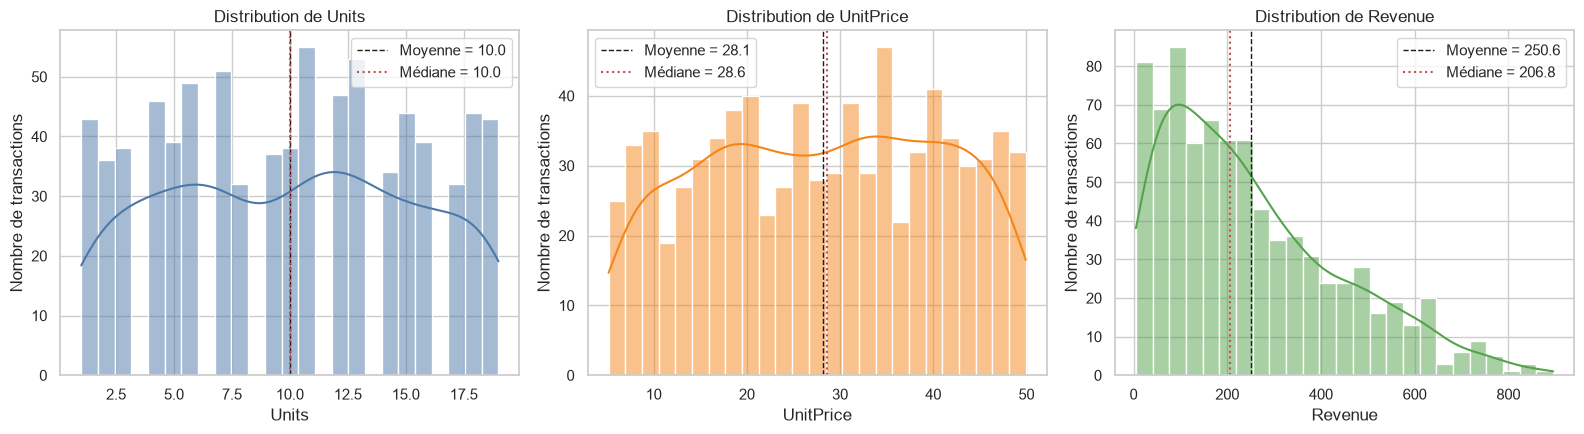

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c, col in zip(axes, ['Units', 'UnitPrice', 'Revenue'], ['#4C78A8', '#F58518', '#54A24B']):
    sns.histplot(df[c], bins=25, kde=True, color=col, ax=ax)
    ax.axvline(df[c].mean(), color='k', ls='--', lw=1, label=f'Moyenne = {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='r', ls=':', lw=1.5, label=f'Médiane = {df[c].median():.1f}')
    ax.set_title(f'Distribution de {c}')
    ax.set_xlabel(c)
    ax.set_ylabel('Nombre de transactions')
    ax.legend()
plt.tight_layout(); plt.show()

**Lecture** : `Units` et `UnitPrice` sont quasi uniformes (moyenne ≈ médiane, pas de queue), tandis que `Revenue` est asymétrique à droite : la majorité des transactions est sous 400, avec une longue queue jusqu'à environ 900.

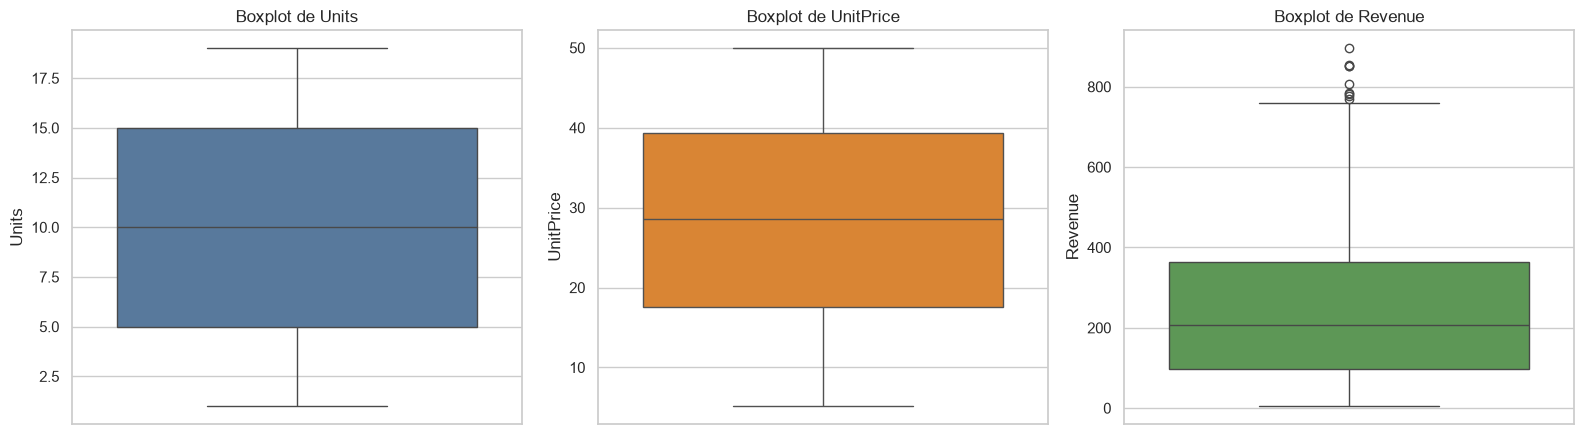

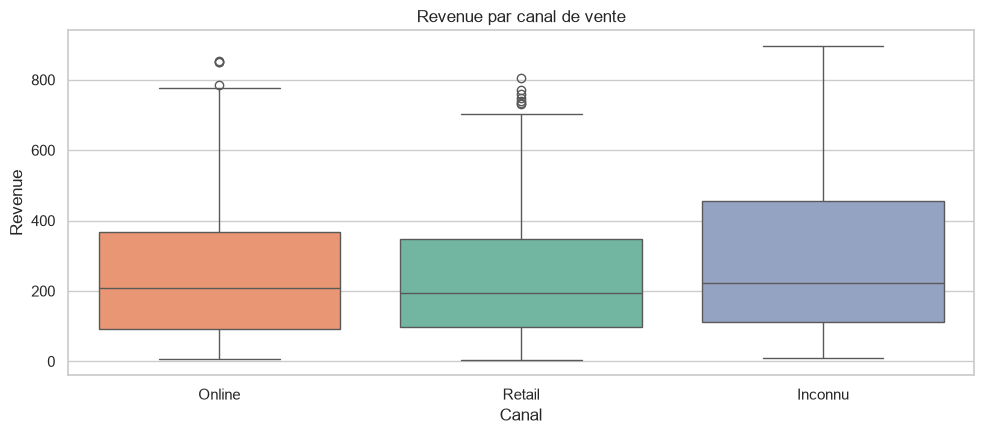

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c, col in zip(axes, ['Units', 'UnitPrice', 'Revenue'], ['#4C78A8', '#F58518', '#54A24B']):
    sns.boxplot(y=df[c], color=col, ax=ax)
    ax.set_title(f'Boxplot de {c}')
    ax.set_ylabel(c)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df, x='Channel', y='Revenue', order=['Online', 'Retail', 'Inconnu'], palette='Set2', hue='Channel', legend=False)
plt.title('Revenue par canal de vente'); plt.xlabel('Canal'); plt.ylabel('Revenue')
plt.tight_layout(); plt.show()

**Lecture** : les boxplots de `Units` et `UnitPrice` sont symétriques sans point extérieur ; `Revenue` montre une médiane de 207 et quelques points au-delà de 764. Par canal, les médianes sont proches (Online 209, Retail 195, Inconnu 221) : les distributions se recouvrent largement.

## Q24 — Matrice de corrélation

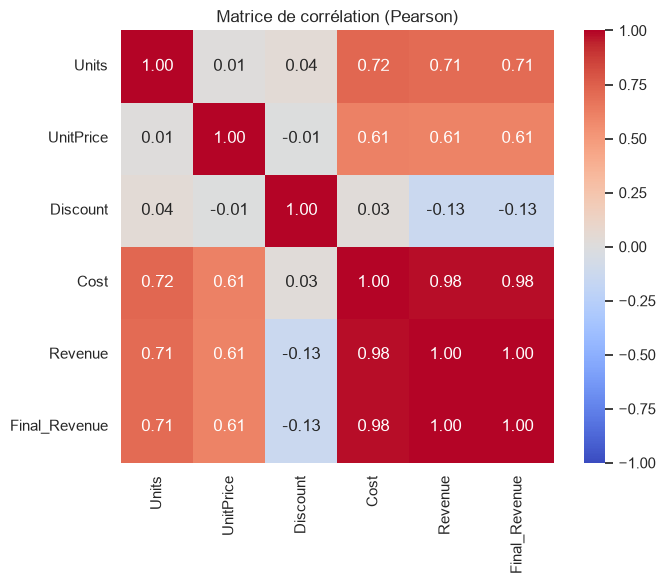

corr
Revenue   Final_Revenue  0.999
Cost      Revenue        0.979
          Final_Revenue  0.978
Units     Cost           0.723
          Revenue        0.707
          Final_Revenue  0.706
UnitPrice Cost           0.613
          Revenue        0.607

In [25]:
corr_cols = ['Units', 'UnitPrice', 'Discount', 'Cost', 'Revenue', 'Final_Revenue']
corr = df[corr_cols].corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matrice de corrélation (Pearson)')
plt.tight_layout(); plt.show()

paires = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename('corr')
display(paires.reindex(paires.abs().sort_values(ascending=False).index).round(3).to_frame().head(8))

**Lecture** : les corrélations les plus fortes sont mécaniques : `Revenue`–`Final_Revenue` (0,999) et `Cost`–`Revenue` (0,979). Les relations « réelles » sont modérées : `Units`–`Cost` (0,72) et `UnitPrice`–`Cost` (0,61) ; `Units` et `UnitPrice` sont indépendantes (0,01) ; `Discount` est faiblement liée à `Revenue` (−0,13).

Une corrélation mesure une association linéaire, pas une relation de cause à effet : une variable tierce, la coïncidence ou un sens de causalité inverse peuvent l'expliquer. Par ailleurs, `Cost`, `Revenue` et `Final_Revenue` sont **calculées à partir de** `Units`, `UnitPrice` et `Discount` : leurs corrélations élevées sont mécaniques (redondance de l'information) et ne constituent pas un résultat d'analyse.

## Q25 — Dispersion relative

In [26]:
disp = pd.DataFrame({
    'Écart-type': df[num_cols].std(),
    'Moyenne': df[num_cols].mean(),
    'CV (écart-type / moyenne)': df[num_cols].std() / df[num_cols].mean(),
    'IQR / médiane': (df[num_cols].quantile(.75) - df[num_cols].quantile(.25)) / df[num_cols].median().replace(0, np.nan),
})
display(disp.sort_values('CV (écart-type / moyenne)', ascending=False).round(3))

,Écart-type,Moyenne,CV (écart-type / moyenne),IQR / médiane
Discount,0.108,0.109,0.986,2.000
Revenue,189.276,250.585,0.755,1.291
Cost,209.871,282.042,0.744,1.201
Units,5.403,9.999,0.540,1.000
UnitPrice,12.774,28.130,0.454,0.762


**Lecture** : comparer les écarts-types n'aurait pas de sens (`Cost` : 210 contre `Discount` : 0,11, échelles différentes). Le **coefficient de variation** (écart-type / moyenne) est sans unité : `Discount` ressort en tête (0,99), mais sa moyenne est proche de 0 avec beaucoup de zéros, ce qui gonfle le CV. Parmi les variables monétaires, `Revenue` (0,76) est plus dispersée que `Cost` (0,74), `Units` (0,54) et `UnitPrice` (0,45). L'IQR / médiane confirme le classement.

## Q26 — Constats chiffrés et limite

In [27]:
ca_total = df.Revenue.sum()
print(f'Revenue total : {ca_total:,.0f} | Revenue moyen par transaction : {df.Revenue.mean():.1f} | médiane : {df.Revenue.median():.1f}')
print(f'Part des transactions avec remise > 0 : {(df.Discount > 0).mean():.1%}')
top10 = df.Revenue.nlargest(int(len(df) * 0.10)).sum() / ca_total
print(f'Part du Revenue réalisée par les 10 % de transactions les plus élevées : {top10:.1%}')
print(f'Écart Cost - Revenue (remises accordées) : {df.Cost.sum() - ca_total:,.0f} ({1 - ca_total / df.Cost.sum():.1%} du montant brut)')

Revenue total : 200,468 | Revenue moyen par transaction : 250.6 | médiane : 206.8
Part des transactions avec remise > 0 : 57.4%
Part du Revenue réalisée par les 10 % de transactions les plus élevées : 25.8%
Écart Cost - Revenue (remises accordées) : 25,165 (11.2% du montant brut)


**Constats** : (1) le Revenue total est de 200 468 pour 800 transactions (moyenne 250,6, médiane 206,8) et 57,4 % des transactions bénéficient d'une remise, soit 11,2 % du montant brut accordé en remises ; (2) les 10 % de transactions les plus élevées réalisent 25,8 % du Revenue. **Limite** : l'analyse descriptive ne dit rien sur les causes, `Cost` n'est pas un coût d'achat (pas de marge), l'heure est peu fiable, et les modalités « Inconnu » (Channel 11 %, PaymentType 7 %) ainsi que le ProductID 210 absent du référentiel (11 % des lignes) restent à valider.

# Partie 5 — Interrogations et filtrage avec Pandas

## Q27 — Units > 10

In [28]:
ventes_q27 = df[df.Units > 10]
print('Lignes retournées :', len(ventes_q27))
display(ventes_q27.head(10))

Lignes retournées : 391


,OrderID,Date,OrderTime,Region,City,StoreID,Channel,CustomerID,ProductID,Units,UnitPrice,Discount,PromoFlag,PaymentType,OrderTime_Format,OrderHour,Cost,Revenue,Final_Revenue,Zone,Direction
3,1004,2025-04-29,NaN,Centre West,Kasserine,15,Online,506,208,15,30.39,0.0,False,Credit,Manquant,NaN,455.85,455.850,455.8500,Centre,West
4,1005,2025-04-03,41:04.8,Centre East,Sousse,11,Online,501,209,15,32.31,0.0,False,Credit,MM:SS.d,NaN,484.65,484.650,484.6500,Centre,East
5,1006,2024-09-07,13:33.6,North East,Manouba,15,Retail,507,205,12,36.24,0.2,False,Credit,MM:SS.d,NaN,434.88,347.904,347.9040,North,East
7,1008,2024-12-13,11:07:48,Centre West,Kasserine,12,Online,503,200,15,30.95,0.0,False,Cash,HH:MM:SS,11.0,464.25,464.250,464.2500,Centre,West
8,1009,2024-04-05,57:55.2,Centre West,Gafsa,12,Online,502,202,11,5.49,0.2,False,Credit,MM:SS.d,NaN,60.39,48.312,48.3120,Centre,West
10,1011,2024-07-27,NaN,North West,Jendouba,13,Retail,503,209,14,41.54,0.1,True,Credit,Manquant,NaN,581.56,523.404,497.2338,North,West
11,1012,2024-11-05,17:31.2,North East,Ariana,11,Online,506,209,12,6.61,0.1,False,Paypal,MM:SS.d,NaN,79.32,71.388,71.3880,North,East
12,1013,2024-06-02,NaN,North East,Bizerte,15,Inconnu,506,208,14,36.61,0.0,True,Paypal,Manquant,NaN,512.54,512.540,486.9130,North,East
13,1014,2024-05-25,45:55.2,North West,Ayn Draham,10,Retail,503,209,17,20.70,0.2,False,Paypal,MM:SS.d,NaN,351.90,281.520,281.5200,North,West
15,1016,2025-06-09,48:07.2,South East,Medenine,12,Online,502,203,11,49.17,0.0,False,Credit,MM:SS.d,NaN,540.87,540.870,540.8700,South,East


## Q28 — Credit ou Paypal et Revenue ≥ 200

In [29]:
ventes_q28 = df[((df.PaymentType == 'Credit') | (df.PaymentType == 'Paypal')) & (df.Revenue >= 200)]
print('Lignes retournées :', len(ventes_q28))
display(ventes_q28.head(10))

Lignes retournées : 256


,OrderID,Date,OrderTime,Region,City,StoreID,Channel,CustomerID,ProductID,Units,UnitPrice,Discount,PromoFlag,PaymentType,OrderTime_Format,OrderHour,Cost,Revenue,Final_Revenue,Zone,Direction
1,1002,2025-11-09,51:52.8,Centre East,Monastir,11,Online,506,203,8,33.77,0.1,True,Credit,MM:SS.d,NaN,270.16,243.144,230.9868,Centre,East
2,1003,2025-06-20,19:43:24,Centre East,Mahdia,15,Online,502,202,7,31.08,0.0,False,Credit,HH:MM:SS,19.0,217.56,217.560,217.5600,Centre,East
3,1004,2025-04-29,NaN,Centre West,Kasserine,15,Online,506,208,15,30.39,0.0,False,Credit,Manquant,NaN,455.85,455.850,455.8500,Centre,West
4,1005,2025-04-03,41:04.8,Centre East,Sousse,11,Online,501,209,15,32.31,0.0,False,Credit,MM:SS.d,NaN,484.65,484.650,484.6500,Centre,East
5,1006,2024-09-07,13:33.6,North East,Manouba,15,Retail,507,205,12,36.24,0.2,False,Credit,MM:SS.d,NaN,434.88,347.904,347.9040,North,East
10,1011,2024-07-27,NaN,North West,Jendouba,13,Retail,503,209,14,41.54,0.1,True,Credit,Manquant,NaN,581.56,523.404,497.2338,North,West
12,1013,2024-06-02,NaN,North East,Bizerte,15,Inconnu,506,208,14,36.61,0.0,True,Paypal,Manquant,NaN,512.54,512.540,486.9130,North,East
13,1014,2024-05-25,45:55.2,North West,Ayn Draham,10,Retail,503,209,17,20.70,0.2,False,Paypal,MM:SS.d,NaN,351.90,281.520,281.5200,North,West
14,1015,2024-03-24,04:04.8,South West,Kebili,12,Online,507,210,8,46.30,0.0,False,Paypal,MM:SS.d,NaN,370.40,370.400,370.4000,South,West
15,1016,2025-06-09,48:07.2,South East,Medenine,12,Online,502,203,11,49.17,0.0,False,Credit,MM:SS.d,NaN,540.87,540.870,540.8700,South,East


Chaque condition est entre parenthèses car `&` et `|` ont une priorité plus forte que les comparateurs (`==`, `>=`) : sans parenthèses, Python lèverait une erreur ou évaluerait une expression erronée. Les deux modes de paiement sont reliés par `|` (OU) puis combinés avec la condition de revenu par `&` (ET), le OU étant lui-même parenthésé pour que le ET s'applique à l'ensemble.

## Q29 — Discount > 0 et PromoFlag

In [30]:
remise = df.Discount > 0
promo = df.PromoFlag

ventes_q29 = df[remise & promo]
repartition = pd.Series({
    'Remise ET promo': (remise & promo).sum(),
    'Remise seulement': (remise & ~promo).sum(),
    'Promo seulement': (~remise & promo).sum(),
    'Aucune des deux': (~remise & ~promo).sum(),
})
display(repartition.to_frame('lignes').assign(pourcentage=lambda t: (t.lignes / len(df) * 100).round(1)))
print('Une seule condition vraie (remise XOR promo) :', (remise ^ promo).sum(), '| Somme des 4 cas =', repartition.sum(), '= nb de lignes', len(df))
display(ventes_q29.head(10))

,lignes,pourcentage
Remise ET promo,122,15.2
Remise seulement,337,42.1
Promo seulement,90,11.2
Aucune des deux,251,31.4


Une seule condition vraie (remise XOR promo) : 427 | Somme des 4 cas = 800 = nb de lignes 800


,OrderID,Date,OrderTime,Region,City,StoreID,Channel,CustomerID,ProductID,Units,UnitPrice,Discount,PromoFlag,PaymentType,OrderTime_Format,OrderHour,Cost,Revenue,Final_Revenue,Zone,Direction
1,1002,2025-11-09,51:52.8,Centre East,Monastir,11,Online,506,203,8,33.77,0.10,True,Credit,MM:SS.d,NaN,270.16,243.1440,230.986800,Centre,East
10,1011,2024-07-27,NaN,North West,Jendouba,13,Retail,503,209,14,41.54,0.10,True,Credit,Manquant,NaN,581.56,523.4040,497.233800,North,West
22,1023,2025-03-20,20:28.8,South East,Gabes,12,Online,502,205,2,18.08,0.20,True,Paypal,MM:SS.d,NaN,36.16,28.9280,27.481600,South,East
26,1027,2025-04-06,20:48:24,South East,Gabes,15,Retail,508,203,15,19.15,0.25,True,Inconnu,HH:MM:SS,20.0,287.25,215.4375,204.665625,South,East
35,1036,2025-11-28,40:14.4,Centre West,Gafsa,10,Online,501,203,4,9.37,0.20,True,Credit,MM:SS.d,NaN,37.48,29.9840,28.484800,Centre,West
45,1046,2025-10-23,17:20:24,North West,Ayn Draham,13,Online,502,209,13,49.53,0.25,True,Cash,HH:MM:SS,17.0,643.89,482.9175,458.771625,North,West
48,1049,2024-12-08,33:02.4,North East,Bizerte,14,Retail,508,208,2,10.86,0.20,True,Paypal,MM:SS.d,NaN,21.72,17.3760,16.507200,North,East
49,1050,2025-10-01,45:43.2,North West,Ayn Draham,11,Inconnu,507,208,5,22.79,0.20,True,Paypal,MM:SS.d,NaN,113.95,91.1600,86.602000,North,West
57,1058,2025-06-18,58:31.2,North East,Ben Arous,13,Online,507,202,5,23.77,0.25,True,Paypal,MM:SS.d,NaN,118.85,89.1375,84.680625,North,East
62,1063,2024-12-02,11:07:24,South West,Gafsa,10,Retail,507,210,5,47.23,0.30,True,Credit,HH:MM:SS,11.0,236.15,165.3050,157.039750,South,West


**Lecture** : 122 ventes cumulent remise et promotion ; 337 ont une remise seule et 90 une promotion seule, soit 427 avec une seule condition vraie (les 4 cas totalisent bien 800). `PromoFlag` n'implique donc pas `Discount` > 0 : leur signification respective doit être confirmée.

## Q30 — North East / South West et quantités dans le top 25 %

In [31]:
seuil = df.Units.quantile(0.75)
masque_region = df.Region.isin(['North East', 'South West'])
ventes_q30 = df[masque_region & (df.Units >= seuil)]
print(f'Seuil (quantile 75 % de Units) : {seuil}')
print('Part des ventes avec Units >= seuil :', f'{(df.Units >= seuil).mean():.1%}')
print('Lignes retournées :', len(ventes_q30))
display(ventes_q30.head(10))

Seuil (quantile 75 % de Units) : 15.0
Part des ventes avec Units >= seuil : 25.2%
Lignes retournées : 60


,OrderID,Date,OrderTime,Region,City,StoreID,Channel,CustomerID,ProductID,Units,UnitPrice,Discount,PromoFlag,PaymentType,OrderTime_Format,OrderHour,Cost,Revenue,Final_Revenue,Zone,Direction
19,1020,2025-06-15,NaN,South West,Tozeur,15,Online,506,205,15,10.97,0.0,False,Credit,Manquant,NaN,164.55,164.550,164.550,South,West
36,1037,2025-08-31,41:04.8,North East,Zaghouan,12,Retail,507,210,18,37.77,0.2,False,Cash,MM:SS.d,NaN,679.86,543.888,543.888,North,East
43,1044,2024-11-13,06:02.4,South West,Gafsa,14,Retail,503,205,18,42.25,0.0,False,Paypal,MM:SS.d,NaN,760.50,760.500,760.500,South,West
47,1048,2024-08-10,NaN,North East,Ariana,13,Online,506,210,18,17.53,0.0,False,Inconnu,Manquant,NaN,315.54,315.540,315.540,North,East
50,1051,2024-10-14,41:50.4,North East,Bizerte,12,Inconnu,508,209,17,32.94,0.1,False,Credit,MM:SS.d,NaN,559.98,503.982,503.982,North,East
51,1052,2024-12-10,12:28.8,South West,Tozeur,10,Online,506,202,17,42.76,0.1,False,Paypal,MM:SS.d,NaN,726.92,654.228,654.228,South,West
85,1086,2025-04-04,06:31.2,South West,Gafsa,11,Online,508,200,15,38.66,0.0,False,Cash,MM:SS.d,NaN,579.90,579.900,579.900,South,West
86,1087,2024-08-08,54:55.2,North East,Nabeul,15,Online,507,200,15,41.31,0.0,False,Credit,MM:SS.d,NaN,619.65,619.650,619.650,North,East
96,1097,2024-05-08,56:52.8,South West,Gafsa,15,Online,507,202,19,30.20,0.0,False,Paypal,MM:SS.d,NaN,573.80,573.800,573.800,South,West
106,1107,2024-04-29,15:28.8,South West,Gafsa,15,Online,503,205,15,48.74,0.2,False,Paypal,MM:SS.d,NaN,731.10,584.880,584.880,South,West


**Lecture** : le seuil est le 3ᵉ quartile de `Units` (15), calculé sur toutes les ventes ; on retient `Units ≥ 15` (la variable étant discrète, cela couvre 25,2 % des ventes au lieu de 25 %). 60 ventes de North East ou South West remplissent la condition.

## Q31 — query() et loc[]

In [32]:
q27_query = df.query('Units > 10')
q28_query = df.query("PaymentType in ['Credit', 'Paypal'] and Revenue >= 200")
q30_loc = df.loc[df.Region.isin(['North East', 'South West']) & (df.Units >= seuil)]

print('Q27 identique :', q27_query.equals(ventes_q27), len(q27_query))
print('Q28 identique :', q28_query.equals(ventes_q28), len(q28_query))
print('Q30 identique :', q30_loc.equals(ventes_q30), len(q30_loc))

Q27 identique : True 391
Q28 identique : True 256
Q30 identique : True 60


- **Masques booléens** : très flexibles, mais verbeux (répétition de `df.`, parenthèses obligatoires, risque d'oubli).
- **`query()`** : syntaxe proche du langage naturel (`and`, `in`), plus lisible pour des filtres multiples ; elle utilise des chaînes, donc moins de vérification statique et une référence aux variables Python via `@`.
- **`loc[]`** : combine filtre de lignes et sélection de colonnes en une instruction et permet aussi l'affectation sans `SettingWithCopyWarning`.
Les trois approches donnent ici exactement les mêmes résultats ; `query()` est la plus lisible pour des conditions simples, les masques pour des conditions complexes ou dynamiques.

# Partie 6 — Agrégations et analyse par segments

## Q32 — Performance par région

In [33]:
region_stats = (df.groupby('Region')
                  .agg(Transactions=('OrderID', 'count'),
                       Quantite_totale=('Units', 'sum'),
                       Revenue_total=('Revenue', 'sum'),
                       Revenue_moyen=('Revenue', 'mean'),
                       Final_Revenue_total=('Final_Revenue', 'sum'))
                  .sort_values('Revenue_total', ascending=False))
display(region_stats.round(1))
print('Contrôle : somme des régions =', round(region_stats.Revenue_total.sum(), 1), '| Revenue total =', round(df.Revenue.sum(), 1))

,Transactions,Quantite_totale,Revenue_total,Revenue_moyen,Final_Revenue_total
Region,,,,,
Centre East,144,1532,41470.7,288.0,40802.3
Centre West,140,1458,35143.1,251.0,34733.9
North East,144,1440,34562.0,240.0,34229.7
South East,138,1314,32067.8,232.4,31604.2
North West,110,1138,29832.7,271.2,29469.1
South West,124,1117,27392.0,220.9,26993.1


Contrôle : somme des régions = 200468.3 | Revenue total = 200468.3


**Lecture** : `Centre East` arrive en tête avec un Revenue de 41 471 pour 144 transactions et 1 532 unités, devant `Centre West` (35 143) et `North East` (34 562) ; `South West` ferme le classement (27 392). Le `Revenue_moyen` ne suit pas le même ordre : `North West` (271) est deuxième alors qu'elle n'a que 110 transactions. `Final_Revenue` est partout inférieur à `Revenue` (−1,3 % au total) à cause de la remise promotionnelle de 5 %. La somme des régions égale bien le Revenue total (200 468).

## Q33 — Région × canal de vente

Transactions  Quantite_totale  Revenue_total
Region      Channel                                              
Centre East Inconnu            14              134         3553.1
            Online             84              928        26109.0
            Retail             46              470        11808.7
Centre West Inconnu            17              218         6749.1
            Online             75              718        16318.1
            Retail             48              522        12075.9
North East  Inconnu            15              176         4349.5
            Online             76              742        17606.4
            Retail             53              522        12606.1
North West  Inconnu            11               90         2437.7
            Online             61              691        18107.4
            Retail             38              357         9287.6
South East  Inconnu            15              149         3552.2
            Online             79              732        18598.6
            Retail             44              433         9917.0
South West  Inconnu            17              172         3975.3
            Online             67              577        14267.3
            Retail             40              368         9149.3

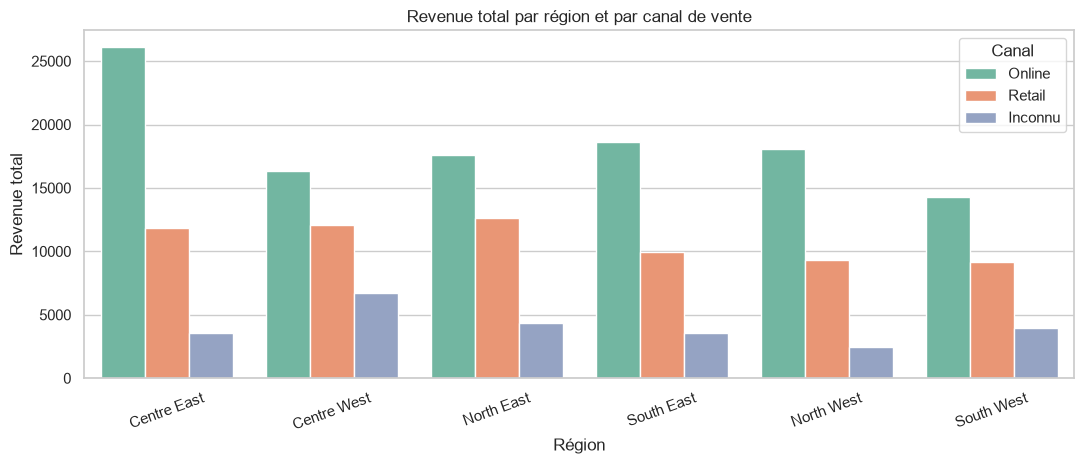

In [34]:
ordre_canaux = ['Online', 'Retail', 'Inconnu']
region_canal = (df.groupby(['Region', 'Channel'])
                  .agg(Transactions=('OrderID', 'count'),
                       Quantite_totale=('Units', 'sum'),
                       Revenue_total=('Revenue', 'sum'))
                  .round(1))
display(region_canal)

plt.figure(figsize=(11, 4.8))
sns.barplot(data=region_canal.reset_index(), x='Region', y='Revenue_total', hue='Channel',
            order=region_stats.index, hue_order=ordre_canaux, palette='Set2')
plt.title('Revenue total par région et par canal de vente')
plt.xlabel('Région'); plt.ylabel('Revenue total')
plt.xticks(rotation=20)
plt.legend(title='Canal')
plt.tight_layout(); plt.show()

**Lecture** : le canal `Online` domine dans les six régions ; la cellule la plus forte est `Centre East` / `Online` (26 109 pour 84 transactions, soit 13,0 % du Revenue total). Le poids du `Retail` varie : il atteint 74 % du Revenue `Online` à `Centre West` mais seulement 51 % à `North West` (9 288 contre 18 107). `South West` a le plus faible Revenue `Online` (14 267). La modalité « Inconnu » pèse jusqu'à 6 749 à `Centre West` (17 ventes, 218 unités) : cette incertitude sur le canal peut modifier la lecture d'une région.

## Q34 — Cost > 100 par type de paiement

In [35]:
cost100 = df[df.Cost > 100]
print('Ventes avec Cost > 100 :', len(cost100), 'sur', len(df))
print('PaymentType manquant (données dédoublonnées) :', sales_raw.drop_duplicates().PaymentType.isna().sum(),
      '| NaN restants dans df :', df.PaymentType.isna().sum(),
      '| modalité « Inconnu » dans Cost > 100 :', (cost100.PaymentType == 'Inconnu').sum())

par_paiement = (cost100.groupby('PaymentType')
                       .agg(Transactions=('OrderID', 'count'), Revenue_total=('Revenue', 'sum'))
                       .sort_values('Revenue_total', ascending=False))
display(par_paiement.round(1))

# Contrôle : sans traitement explicite, groupby() ignorerait les NaN et ferait « disparaître » ces ventes
brut = df.assign(PaymentType=df.PaymentType.replace('Inconnu', np.nan))
sans_traitement = brut[brut.Cost > 100].groupby('PaymentType').Revenue.sum()
print('\nRevenue (Cost > 100) avec « Inconnu » :', round(par_paiement.Revenue_total.sum(), 1),
      '| groupby sans traitement :', round(sans_traitement.sum(), 1),
      '| ventes perdues :', round(par_paiement.Revenue_total.sum() - sans_traitement.sum(), 1))

Ventes avec Cost > 100 : 620 sur 800
PaymentType manquant (données dédoublonnées) : 57 | NaN restants dans df : 0 | modalité « Inconnu » dans Cost > 100 : 47


,Transactions,Revenue_total
PaymentType,,
Cash,191,60112.4
Credit,203,59817.7
Paypal,179,58460.8
Inconnu,47,13356.1



Revenue (Cost > 100) avec « Inconnu » : 191747.0 | groupby sans traitement : 178390.8 | ventes perdues : 13356.1


**Lecture** : 620 ventes sur 800 (77,5 %) ont un `Cost` > 100. Les trois modes connus sont très proches : `Cash` 60 112 (191 transactions), `Credit` 59 818 (203) et `Paypal` 58 461 (179). **Traitement des manquants** : les 57 `PaymentType` manquants (après dédoublonnage) ont reçu la modalité « Inconnu » en Q7/Q11 ; 47 d'entre elles ont un `Cost` > 100 et représentent 13 356 de Revenue. Sans ce traitement, `groupby()` ignorerait silencieusement les `NaN` et ces 13 356 (7,0 % du total filtré) disparaîtraient du tableau : le total serait faux (178 391 au lieu de 191 747).

## Q35 — Performance par catégorie et produit (jointure avec `products`)

In [36]:
ventes_prod = df.merge(products, on='ProductID', how='left', validate='m:1')
ventes_prod['ProductName'] = ventes_prod.ProductName.fillna('Non référencé')
ventes_prod['Category'] = ventes_prod.Category.fillna('Non référencé')

def perf(groupe):
    t = (ventes_prod.groupby(groupe)
                    .agg(Transactions=('OrderID', 'count'), Quantite_totale=('Units', 'sum'),
                         Revenue_total=('Revenue', 'sum'), Revenue_moyen=('Revenue', 'mean'))
                    .sort_values('Revenue_total', ascending=False))
    t['Part Revenue %'] = (t.Revenue_total / ventes_prod.Revenue.sum() * 100)
    return t.round(2)

print('Par catégorie'); display(perf('Category'))
print('Par catégorie et produit'); display(perf(['Category', 'ProductName']))

orphelines = ventes_prod[ventes_prod.ProductName == 'Non référencé']
print('ProductID sans correspondance :', [int(p) for p in sorted(orphelines.ProductID.unique())])
print(f'Impact : {len(orphelines)} lignes ({len(orphelines) / len(df):.1%}), '
      f'Revenue {orphelines.Revenue.sum():,.0f} ({orphelines.Revenue.sum() / df.Revenue.sum():.1%} du total), '
      f'quantité {orphelines.Units.sum()} ({orphelines.Units.sum() / df.Units.sum():.1%})')
jamais_vendus = products[~products.ProductID.isin(df.ProductID)]
print('Produits du référentiel sans aucune vente :', jamais_vendus.ProductName.tolist())

Par catégorie


,Transactions,Quantite_totale,Revenue_total,Revenue_moyen,Part Revenue %
Category,,,,,
Electronics,239,2479,60503.59,253.15,30.18
Household,123,1253,33133.56,269.38,16.53
Personal Care,113,1173,30007.36,265.55,14.97
Accessories,119,1156,27059.32,227.39,13.50
Digital Products,118,1060,26241.03,222.38,13.09
Non référencé,88,878,23523.39,267.31,11.73


Par catégorie et produit


,,Transactions,Quantite_totale,Revenue_total,Revenue_moyen,Part Revenue %
Category,ProductName,,,,,
Household,cleaning products,123,1253,33133.56,269.38,16.53
Electronics,iphone,121,1239,30563.09,252.59,15.25
Personal Care,Shampoo,113,1173,30007.36,265.55,14.97
Electronics,Computer,118,1240,29940.50,253.73,14.94
Accessories,watch,119,1156,27059.32,227.39,13.50
Digital Products,E-book,118,1060,26241.03,222.38,13.09
Non référencé,Non référencé,88,878,23523.39,267.31,11.73


ProductID sans correspondance : [210]
Impact : 88 lignes (11.0%), Revenue 23,523 (11.7% du total), quantité 878 (11.0%)
Produits du référentiel sans aucune vente : ['Online course', 'Handbag', 'blender', 'toothpaste']


**Lecture** : `Electronics` est la première catégorie avec 30,2 % du Revenue (`iphone` 15,3 % et `Computer` 14,9 %), suivie de `Household` (16,5 %) dont `cleaning products` est le meilleur produit individuel (33 134). **Produits sans correspondance** : les 88 ventes du `ProductID` **210** (11,0 % des lignes, 878 unités) pèsent 23 523, soit **11,7 % du Revenue** ; elles sont isolées sous le libellé « Non référencé » au lieu d'être supprimées. Parmi les sept produits vendus, le 210 serait le dernier en Revenue total, mais son Revenue moyen par ligne (267) est parmi les plus élevés (3ᵉ). À l'inverse, quatre produits du référentiel (`Online course`, `Handbag`, `blender`, `toothpaste`) n'ont aucune vente.

## Q36 — Part de chaque région dans le Revenue total

,Part du Revenue (%)
Region,
Centre East,20.69
Centre West,17.53
North East,17.24
South East,16.00
North West,14.88
South West,13.66


Somme des parts : 100.0 %
Lignes sans Region (exclues du calcul) : 0


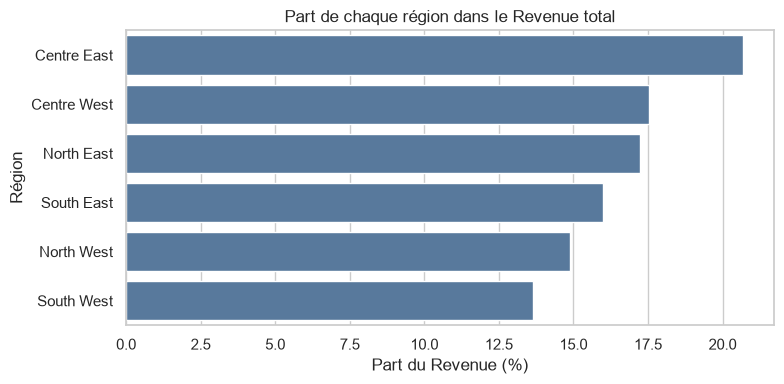

In [37]:
part_region = (region_stats.Revenue_total / df.Revenue.sum() * 100).round(2)
display(part_region.to_frame('Part du Revenue (%)'))
print('Somme des parts :', round(part_region.sum(), 2), '%')
print('Lignes sans Region (exclues du calcul) :', df.Region.isna().sum())
assert np.isclose(region_stats.Revenue_total.sum(), df.Revenue.sum())

plt.figure(figsize=(8, 4))
sns.barplot(x=part_region.values, y=part_region.index, color='#4C78A8')
plt.title('Part de chaque région dans le Revenue total')
plt.xlabel('Part du Revenue (%)'); plt.ylabel('Région')
plt.tight_layout(); plt.show()

**Lecture** : `Centre East` représente 20,7 % du Revenue, `South West` 13,7 %. Les six parts totalisent 100,00 % : aucune ligne n'a de `Region` manquante, donc aucune n'est exclue du calcul. Si des lignes avaient été exclues, il aurait fallu calculer les parts sur le total retenu et le préciser, sinon la somme n'aurait pas été de 100 %.

## Q37 — Pourquoi `groupby()` ?

In [38]:
prix_simple = df.UnitPrice.mean()
prix_pondere = np.average(df.UnitPrice, weights=df.Units)
print('Prix unitaire moyen simple :', round(prix_simple, 2), '| pondéré par les quantités :', round(prix_pondere, 2))

ex = df.groupby('Region').agg(Transactions=('OrderID', 'count'), Revenue_moyen=('Revenue', 'mean'), Revenue_total=('Revenue', 'sum'))
display(ex.sort_values('Revenue_moyen', ascending=False).round(1))

Prix unitaire moyen simple : 28.13 | pondéré par les quantités : 28.21


,Transactions,Revenue_moyen,Revenue_total
Region,,,
Centre East,144,288.0,41470.7
North West,110,271.2,29832.7
Centre West,140,251.0,35143.1
North East,144,240.0,34562.0
South East,138,232.4,32067.8
South West,124,220.9,27392.0


`groupby()` applique le schéma **découper – appliquer – combiner** : on découpe le tableau par segment (région, canal…), on calcule un indicateur par segment, puis on assemble un résultat lisible, sans boucle ni calcul manuel.

- **Somme** (`sum`) : mesure le **volume total** (Revenue, quantités) ; elle dépend du nombre de lignes du segment.
- **Moyenne** (`mean`) : mesure le **niveau typique** par ligne ; elle est indépendante de la taille du segment.
- **Nombre de transactions** (`count`) : mesure l'**activité**. Les trois sont liées : somme = moyenne × nombre de transactions.

**Exemple de moyenne trompeuse** : `North West` a le 2ᵉ meilleur Revenue moyen par transaction (271) mais seulement le 5ᵉ Revenue total, parce qu'elle compte 110 transactions contre 144 pour `Centre East`. Classer les régions sur la seule moyenne ferait croire à une performance supérieure alors que le volume est faible. De même, le prix unitaire moyen simple (28,13) diffère du prix moyen **pondéré par les quantités** (28,21), qui est celui réellement payé par unité vendue ; et la moyenne de moyennes de groupes de tailles inégales n'est pas la moyenne globale.

# Partie 7 — Jointures et contrôle de l'intégrité

## Q38 — Jointure interne ventes / produits

In [39]:
n_ventes = len(df)
jointure_interne = df.merge(products, on='ProductID', how='inner')
print('Lignes de ventes avant la jointure :', n_ventes)
print('Lignes après jointure interne      :', len(jointure_interne), '| lignes perdues :', n_ventes - len(jointure_interne))
print('Revenue avant :', round(df.Revenue.sum(), 1), '| après :', round(jointure_interne.Revenue.sum(), 1),
      '| perdu :', round(df.Revenue.sum() - jointure_interne.Revenue.sum(), 1))

Lignes de ventes avant la jointure : 800
Lignes après jointure interne      : 712 | lignes perdues : 88
Revenue avant : 200468.3 | après : 176944.9 | perdu : 23523.4


**Lecture** : la jointure interne passe de 800 à 712 lignes. Les 88 ventes du `ProductID` 210 disparaissent, soit 23 523 de Revenue (−11,7 %). Une jointure interne est donc **destructive** quand l'intégrité référentielle n'est pas garantie : les totaux calculés après cette jointure sous-estiment l'activité sans que rien ne le signale.

## Q39 — Jointure gauche

In [40]:
jointure_gauche = df.merge(products, on='ProductID', how='left')
sans_correspondance = jointure_gauche[jointure_gauche.ProductName.isna()]
print('Lignes après jointure gauche :', len(jointure_gauche), '(= nombre de ventes :', len(jointure_gauche) == n_ventes, ')')
print('Ventes sans correspondance   :', len(sans_correspondance), f'({len(sans_correspondance) / n_ventes:.1%})')
print('ProductID concernés          :', sans_correspondance.ProductID.unique().tolist())
display(sans_correspondance[['OrderID', 'Region', 'ProductID', 'Units', 'UnitPrice', 'Revenue']].head())

Lignes après jointure gauche :

 800 (= nombre de ventes : True )
Ventes sans correspondance   : 88 (11.0%)
ProductID concernés          : [210]


,OrderID,Region,ProductID,Units,UnitPrice,Revenue
9,1010,North West,210,3,44.48,133.440
14,1015,South West,210,8,46.30,370.400
18,1019,South East,210,5,9.68,43.560
25,1026,South West,210,10,17.36,173.600
30,1031,Centre West,210,15,25.71,347.085


**Lecture** : la jointure gauche conserve les 800 ventes. 88 lignes (11,0 %) n'ont pas de correspondance, toutes pour le `ProductID` 210 ; leurs colonnes `ProductName` et `Category` valent `NaN`. C'est la jointure à privilégier pour un contrôle d'intégrité, car elle permet d'identifier et de quantifier les écarts au lieu de les masquer.

## Q40 — Unicité de `ProductID` et paramètre `validate`

In [41]:
print('ProductID unique dans products ?', products.ProductID.is_unique, '| doublons :', products.ProductID.duplicated().sum())
ok = df.merge(products, on='ProductID', how='left', validate='many_to_one')
print('validate="many_to_one" : OK,', len(ok), 'lignes')

# Simulation : un doublon dans le référentiel
products_dup = pd.concat([products, products.iloc[[0]]], ignore_index=True)
try:
    df.merge(products_dup, on='ProductID', how='left', validate='many_to_one')
except Exception as e:
    print('\nAvec un doublon dans le référentiel :', type(e).__name__, '-', str(e).splitlines()[0])

sans_controle = df.merge(products_dup, on='ProductID', how='left')
print('Sans validate : lignes', len(sans_controle), 'au lieu de', len(df),
      '| Revenue', round(sans_controle.Revenue.sum(), 1), 'au lieu de', round(df.Revenue.sum(), 1))

ProductID unique dans products ? True | doublons : 0
validate="many_to_one" : OK, 800 lignes

Avec un doublon dans le référentiel : MergeError - Merge keys are not unique in right dataset; not a many-to-one merge
Sans validate : lignes 918 au lieu de 800 | Revenue 226709.3 au lieu de 200468.3


**Lecture** : `ProductID` est unique dans `products` (0 doublon) et `validate='many_to_one'` est accepté : plusieurs ventes pour un produit, un seul produit par vente. **Effet de doublons dans le référentiel** : si un produit était dupliqué, chaque vente le concernant serait dupliquée à la jointure (918 lignes au lieu de 800) et le Revenue serait gonflé (226 709 au lieu de 200 468, +13,1 %) sans message d'erreur. Avec `validate`, pandas lève une `MergeError` et protège contre cette erreur silencieuse.

## Q41 — Indicateur de provenance (`indicator=True`)

In [42]:
indic = df.merge(products, on='ProductID', how='outer', indicator=True)
display(indic._merge.value_counts().to_frame('lignes'))
print('left_only  : ventes dont le ProductID est absent du référentiel :', (indic._merge == 'left_only').sum())
print('right_only : produits du référentiel sans aucune vente         :', (indic._merge == 'right_only').sum())
print('both       : ventes avec correspondance                        :', (indic._merge == 'both').sum())

,lignes
_merge,
both,712
left_only,88
right_only,4


left_only  : ventes dont le ProductID est absent du référentiel : 88
right_only : produits du référentiel sans aucune vente         : 4
both       : ventes avec correspondance                        : 712


**Lecture** : la jointure externe distingue trois catégories : `both` (712 ventes avec correspondance), `left_only` (88 ventes dont le `ProductID` est absent du référentiel) et `right_only` (4 produits du référentiel jamais vendus).

**Actions de gouvernance** : (1) faire valider avec l'équipe produit/catalogue ce qu'est le `ProductID` 210 (nouveau produit, produit retiré ou erreur de saisie) et l'ajouter au référentiel ou le corriger à la source ; (2) imposer un contrôle d'intégrité référentielle à l'enregistrement de la vente (clé étrangère ou liste de valeurs autorisées) ; (3) automatiser ce contrôle (`indicator` + alerte) à chaque chargement ; (4) vérifier si les 4 produits sans vente sont obsolètes ou mal référencés.

## Q42 — Clients n'ayant jamais acheté

Une jointure gauche entre `sales` et `products` s'appuie sur `ProductID` : elle ne relie que des ventes à des produits. Elle ne dit rien sur les clients, pour deux raisons : (1) le fichier `sales` ne contient, par construction, que des clients **ayant acheté** (chaque `CustomerID` y apparaît au moins une fois ; il n'y en a que 6 distincts) ; un client sans achat n'y figure pas et ne peut donc pas être détecté ; (2) la clé de jointure n'est pas `CustomerID`.

Pour identifier les clients inactifs, il faudrait un **référentiel clients** complet (CRM ou fichier `customers.csv` avec `CustomerID`, date d'inscription, etc.). On ferait alors une jointure gauche `clients` → `ventes` sur `CustomerID` avec `indicator=True` : les lignes `left_only` sont les clients sans aucun achat (anti-jointure). Une période d'observation et une date d'inscription seraient aussi utiles pour distinguer les clients inactifs des clients très récents.

# Partie 8 — Analyse métier et recommandations

## Q43 — Région générant le plus de Revenue

,Revenue_total,Part Revenue %,Transactions,Quantite_totale,Revenue_moyen,Unités / transaction,Revenue / unité
Region,,,,,,,
Centre East,41470.68,20.69,144,1532,287.99,10.64,27.07
Centre West,35143.06,17.53,140,1458,251.02,10.41,24.10
North East,34562.02,17.24,144,1440,240.01,10.00,24.00
South East,32067.80,16.00,138,1314,232.38,9.52,24.40
North West,29832.74,14.88,110,1138,271.21,10.35,26.22
South West,27391.95,13.66,124,1117,220.90,9.01,24.52


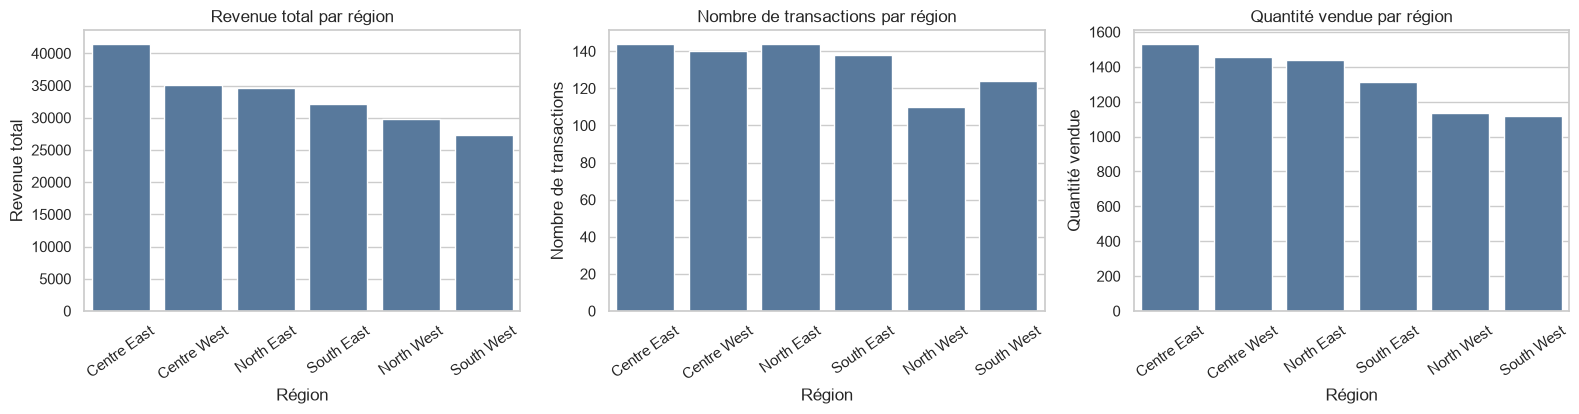

In [43]:
top_region = region_stats.copy()
top_region['Part Revenue %'] = top_region.Revenue_total / df.Revenue.sum() * 100
top_region['Unités / transaction'] = top_region.Quantite_totale / top_region.Transactions
top_region['Revenue / unité'] = top_region.Revenue_total / top_region.Quantite_totale
display(top_region[['Revenue_total', 'Part Revenue %', 'Transactions', 'Quantite_totale',
                    'Revenue_moyen', 'Unités / transaction', 'Revenue / unité']].round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col, titre in zip(axes, ['Revenue_total', 'Transactions', 'Quantite_totale'],
                          ['Revenue total', 'Nombre de transactions', 'Quantité vendue']):
    sns.barplot(x=top_region.index, y=top_region[col], color='#4C78A8', ax=ax)
    ax.set_title(titre + ' par région'); ax.set_xlabel('Région'); ax.set_ylabel(titre)
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show()

**Lecture** : `Centre East` génère le plus de Revenue (41 471, 20,7 %), 18 % de plus que la deuxième région (`Centre West`, 35 143). Elle est aussi à égalité première en nombre de transactions (144, comme `North East`) et première en quantités (1 532). Mais le chiffre d'affaires seul ne mesure pas la performance : son avance vient à la fois du volume et de la valeur par transaction (288 contre 250,6 en moyenne globale ; 10,6 unités par transaction ; 27,1 de Revenue par unité contre 24 à 26 ailleurs). C'est donc la combinaison de plusieurs indicateurs, et non le seul total, qui justifie la lecture.

## Q44 — Type de paiement et Revenue total

In [44]:
paiement = (df.groupby('PaymentType')
              .agg(Transactions=('OrderID', 'count'), Revenue_total=('Revenue', 'sum'), Revenue_moyen=('Revenue', 'mean'))
              .sort_values('Revenue_total', ascending=False))
paiement['Part Revenue %'] = paiement.Revenue_total / df.Revenue.sum() * 100
display(paiement.round(2))

connus = df[df.PaymentType != 'Inconnu']
h, p = stats.kruskal(*[g.Revenue.values for _, g in connus.groupby('PaymentType')])
print(f'Test de Kruskal-Wallis sur Revenue (modes connus) : H = {h:.2f}, p-value = {p:.3f}')
ecart = paiement.Revenue_total.iloc[0] - paiement.Revenue_total.iloc[1]
print('Écart entre les deux premiers modes :', round(ecart, 1), '| Revenue des ventes « Inconnu » :', round(paiement.loc['Inconnu', 'Revenue_total'], 1))

,Transactions,Revenue_total,Revenue_moyen,Part Revenue %
PaymentType,,,,
Credit,259,62667.19,241.96,31.26
Cash,234,62163.41,265.66,31.01
Paypal,250,61844.78,247.38,30.85
Inconnu,57,13792.87,241.98,6.88


Test de Kruskal-Wallis sur Revenue (modes connus) : H = 2.64, p-value = 0.267
Écart entre les deux premiers modes : 503.8 | Revenue des ventes « Inconnu » : 13792.9


**Lecture** : `Credit` est associé au Revenue total le plus élevé (62 667, 31,3 %), mais l'écart avec `Cash` (62 163) et `Paypal` (61 845) est minime (504, soit 0,8 %). `Cash` a le plus fort Revenue moyen par transaction (265,7 contre 242,0 pour `Credit` et 247,4 pour `Paypal`) avec moins de transactions (234 contre 259). Le test de Kruskal-Wallis (p = 0,27) ne détecte aucune différence significative de Revenue entre les trois modes connus. **Effet des manquants** : les 57 ventes « Inconnu » représentent 13 793 de Revenue, soit 27 fois l'écart entre les deux premiers modes : leur attribution réelle pourrait changer le classement, qui est donc indécis.

## Q45 — Segment sous-performant

,Revenue total,Transactions,Revenue moyen,Unités / transaction,Revenue / unité
Indice (moyenne des régions = 100),,,,,
Centre East,124,108,115,107,108
Centre West,105,105,100,104,96
North East,103,108,96,100,96
South East,96,103,93,95,97
North West,89,82,108,104,105
South West,82,93,88,90,98


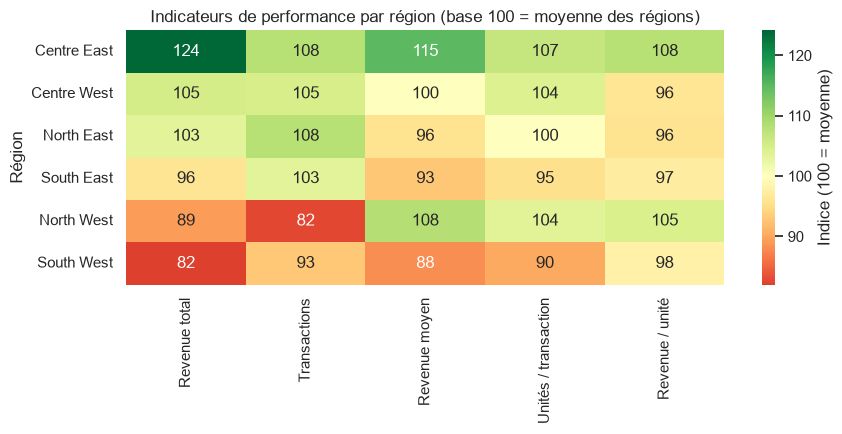

In [45]:
seg = top_region[['Revenue_total', 'Transactions', 'Revenue_moyen', 'Unités / transaction', 'Revenue / unité']].copy()
indice = seg / seg.mean() * 100
indice.columns = ['Revenue total', 'Transactions', 'Revenue moyen', 'Unités / transaction', 'Revenue / unité']
display(indice.round(0).astype(int).rename_axis('Indice (moyenne des régions = 100)'))

plt.figure(figsize=(9, 4.5))
sns.heatmap(indice, annot=True, fmt='.0f', cmap='RdYlGn', center=100, cbar_kws={'label': 'Indice (100 = moyenne)'})
plt.title('Indicateurs de performance par région (base 100 = moyenne des régions)')
plt.ylabel('Région')
plt.tight_layout(); plt.show()

**Lecture** : `South West` est le segment le plus faible en Revenue total (indice 82, base 100 = moyenne des régions), en Revenue moyen par transaction (88) et en unités par transaction (90 ; 9,0 contre 10 en moyenne) ; son nombre de transactions (93) est un peu inférieur à la moyenne. Le Revenue par unité est proche de la moyenne (98) : le prix payé par unité n'est pas en cause, ce sont les **quantités par commande** (et un nombre de transactions un peu inférieur) qui expliquent le retard.

**Faible volume ou faible performance unitaire ?** `North West` est aussi basse en Revenue total (89), mais à cause d'un faible nombre de transactions (110, indice 82) : sa valeur par transaction (108) et par unité (105) est au-dessus de la moyenne. Un faible chiffre d'affaires total peut donc venir d'un **faible volume** (peu de transactions) sans que chaque vente soit moins rentable ; il faut croiser le total avec des indicateurs unitaires avant de conclure à une sous-performance. Le diagnostic des deux régions est différent (augmenter la taille du panier pour `South West`, générer plus de transactions pour `North West`).

## Q46 — Ventes avec et sans promotion

In [46]:
promo_tab = (df.groupby('PromoFlag')
               .agg(Transactions=('OrderID', 'count'), Quantite_moyenne=('Units', 'mean'),
                    Revenue_moyen=('Revenue', 'mean'), Final_Revenue_total=('Final_Revenue', 'sum'),
                    Remise_moyenne=('Discount', 'mean'), Prix_unitaire_moyen=('UnitPrice', 'mean')))
promo_tab.index = promo_tab.index.map({False: 'Sans promo', True: 'Avec promo'})
display(promo_tab.round(2))

for var in ['Units', 'Revenue']:
    u, p = stats.mannwhitneyu(df.loc[df.PromoFlag, var], df.loc[~df.PromoFlag, var])
    print(f'Mann-Whitney sur {var} (promo vs sans promo) : p-value = {p:.3f}')
print('Part de promotions par région :', (df.groupby('Region').PromoFlag.mean() * 100).round(1).to_dict())

,Transactions,Quantite_moyenne,Revenue_moyen,Final_Revenue_total,Remise_moyenne,Prix_unitaire_moyen
PromoFlag,,,,,,
Sans promo,588,10.03,251.27,147748.37,0.11,28.03
Avec promo,212,9.92,248.68,50083.90,0.11,28.39


Mann-Whitney sur Units (promo vs sans promo) : p-value = 0.821
Mann-Whitney sur Revenue (promo vs sans promo) : p-value = 0.857
Part de promotions par région : {'Centre East': 29.9, 'Centre West': 24.3, 'North East': 24.3, 'North West': 20.9, 'South East': 28.3, 'South West': 30.6}


**Lecture** : 212 transactions (26,5 %) portent `PromoFlag = True`. Elles ne se distinguent pas des autres : quantité moyenne 9,92 contre 10,03, Revenue moyen 248,7 contre 251,3, remise moyenne identique (0,11). Les tests de Mann-Whitney ne montrent aucune différence significative (p = 0,82 pour `Units`, p = 0,86 pour `Revenue`). `Final_Revenue` total : 50 084 pour les ventes en promotion, 147 748 pour les autres.

**Peut-on conclure que les promotions causent une hausse des ventes ?** Non, pour trois raisons : (1) c'est une **observation** et non une expérience : les promotions n'ont pas été attribuées au hasard, donc d'autres facteurs (région, produit, période, client) peuvent expliquer les écarts ; (2) on ne connaît pas la situation **sans promotion pour les mêmes ventes** (pas de contrefactuel) ; (3) ici l'association n'existe même pas (pas de hausse), et la région où la part de promotions est la plus élevée (`South West`, 30,6 %) est aussi la plus faible en Revenue. Pour établir un effet causal, il faudrait un test A/B ou une comparaison avant/après contrôlée.

## Q47 — Trois recommandations métier

**1. Remonter le panier moyen de `South West`**
- **Observation** : `South West` est dernière avec 27 392 de Revenue (13,7 %), 9,0 unités par transaction contre 10 en moyenne, et un Revenue moyen de 221 contre 251 en moyenne ; son prix par unité (24,5) est pourtant dans la moyenne.
- **Recommandation** : cibler les quantités par commande (offres de lot, vente additionnelle, seuils de livraison gratuite) plutôt que les prix, et fixer un objectif de 10 unités par transaction.
- **Limite / vérification** : l'analyse ne dispose ni du trafic, ni de la concurrence, ni de la saisonnalité ; il faut descendre au niveau `City` / `StoreID` et dans le temps pour voir si le retard est général ou concentré.

**2. Réévaluer les promotions avant de les généraliser**
- **Observation** : 26,5 % des transactions sont en promotion, mais la quantité moyenne (9,92 contre 10,03) et le Revenue moyen (248,7 contre 251,3) ne sont pas supérieurs ; la remise de 5 % retire 2 636 de Revenue (−1,3 %).
- **Recommandation** : suspendre ou resserrer les promotions peu rentables et passer à des tests A/B par région avant tout déploiement.
- **Limite / vérification** : analyse observationnelle ; la signification exacte de `PromoFlag` (distincte de `Discount` : 90 ventes en promotion sans remise) et la date des campagnes doivent être confirmées.

**3. Fiabiliser les données de référence et de saisie**
- **Observation** : 88 ventes (11,0 % des lignes, 23 523 soit 11,7 % du Revenue) portent un `ProductID` 210 absent du référentiel ; `Channel` est inconnu pour 89 ventes (11,1 %) et `PaymentType` pour 57 (7,1 %) ; ces incertitudes dépassent l'écart entre les deux premiers modes de paiement (504).
- **Recommandation** : rendre `Channel` et `PaymentType` obligatoires à la saisie, mettre à jour le référentiel produit et contrôler `ProductID` à l'enregistrement de la vente.
- **Limite / vérification** : on ignore si le 210 est un vrai produit ou une erreur ; il faut le confirmer auprès du service catalogue, et vérifier la raison des manquants (système, magasin, période) avant de corriger.

## Q48 — Marge commerciale

**Non**, on ne peut pas calculer une marge commerciale réelle avec les colonnes fournies. Dans ce TP, `Cost = UnitPrice × Units` est le **montant brut de vente** au prix catalogue, avant remise : c'est un prix de vente, pas un coût. Le **coût d'acquisition** est ce que l'entreprise paie pour obtenir le produit (achat au fournisseur ou fabrication, transport, droits de douane). Confondre les deux ferait passer un chiffre d'affaires pour un coût, et la « marge » `Revenue − Cost` ne serait en réalité que le montant des remises (11,2 % du brut).

Il faudrait au minimum :
- le **coût d'achat ou de revient unitaire** par `ProductID` (coût des marchandises vendues) ;
- les **frais variables** liés à la vente : logistique, livraison, commissions de paiement (Paypal, carte) ;
- les **retours, remboursements et annulations** ;
- le traitement de la **TVA / taxes** (marge calculée hors taxes) ;
- éventuellement les **coûts de promotion** et les coûts fixes par magasin pour une marge nette.

La marge se calculerait alors par `(Revenue − coût unitaire × Units − frais variables)` ligne par ligne, puis agrégée par produit, catégorie ou région.

# Partie 9 — Efficacité et ouverture Big Data

## Q49 — Opération vectorisée vs boucle Python

In [47]:
import time

big = pd.concat([df[['UnitPrice', 'Units', 'Discount']]] * 250, ignore_index=True)
print('Taille du jeu de test :', f'{len(big):,}', 'lignes')

t0 = time.perf_counter()
rev_vec = big.UnitPrice * big.Units * (1 - big.Discount)
t_vec = time.perf_counter() - t0

t0 = time.perf_counter()
rev_tuples = [r.UnitPrice * r.Units * (1 - r.Discount) for r in big.itertuples(index=False)]
t_tuples = time.perf_counter() - t0

t0 = time.perf_counter()
rev_loop = []
for _, r in big.iterrows():
    rev_loop.append(r.UnitPrice * r.Units * (1 - r.Discount))
t_loop = time.perf_counter() - t0

assert np.allclose(rev_vec, rev_loop) and np.allclose(rev_vec, rev_tuples)
temps = pd.DataFrame({'Temps (s)': [t_vec, t_tuples, t_loop]}, index=['Vectorisée', 'Boucle itertuples()', 'Boucle iterrows()'])
temps['Facteur vs vectorisée'] = temps['Temps (s)'] / t_vec
display(temps.round(4))

Taille du jeu de test : 200,000 lignes


,Temps (s),Facteur vs vectorisée
Vectorisée,0.0017,1.0000
Boucle itertuples(),0.0991,58.8024
Boucle iterrows(),5.8399,3464.5968


**Lecture** : sur 200 000 lignes, le calcul de `UnitPrice × Units × (1 − Discount)` prend quelques millisecondes en version vectorisée, environ 0,1 s avec une boucle `itertuples()` (quelques dizaines de fois plus lent) et environ 5 s avec `iterrows()` (plusieurs centaines à plusieurs milliers de fois plus lent) ; les temps exacts varient d'une exécution à l'autre (cf. tableau ci-dessus), mais l'ordre de grandeur reste le même. Les trois versions donnent les mêmes valeurs (`np.allclose`). **Explication** : l'opération vectorisée est exécutée par le code compilé de NumPy, sur des tableaux contigus en mémoire, sans interpréteur Python ligne par ligne ; `iterrows()` crée en plus une `Series` pour chaque ligne, d'où son coût. Règle : pas de boucle sur les lignes d'un DataFrame quand une opération vectorisée, `np.where` ou `groupby` existe.

## Q50 — Empreinte mémoire et optimisation des types

In [48]:
mem = df.memory_usage(deep=True).drop('Index')
display((mem.sort_values(ascending=False) / 1024).round(1).to_frame('Ko').assign(Type=df.dtypes.astype(str)).head(8))

df_opt = df.copy()
for c in ['Region', 'City', 'Channel', 'PaymentType', 'Zone', 'Direction', 'OrderTime_Format']:
    df_opt[c] = df_opt[c].astype('category')
for c in ['OrderID', 'StoreID', 'CustomerID', 'ProductID', 'Units']:
    df_opt[c] = pd.to_numeric(df_opt[c], downcast='integer')
for c in ['UnitPrice', 'Discount', 'Cost', 'Revenue', 'Final_Revenue']:
    df_opt[c] = df_opt[c].astype('float32')

avant, apres = df.memory_usage(deep=True).sum(), df_opt.memory_usage(deep=True).sum()
print(f'Mémoire avant : {avant / 1024:.1f} Ko | après : {apres / 1024:.1f} Ko | gain : {1 - apres / avant:.1%}')
comp = pd.DataFrame({'Avant (Ko)': mem / 1024, 'Après (Ko)': df_opt.memory_usage(deep=True).drop('Index') / 1024})
display(comp[(comp['Avant (Ko)'] - comp['Après (Ko)']).abs() > 0.5].round(1))

# Cohérence des valeurs et des agrégats
assert df_opt.Units.sum() == df.Units.sum() and len(df_opt) == len(df)
assert np.isclose(df_opt.Revenue.astype('float64').sum(), df.Revenue.sum(), rtol=1e-5)
agg_a = df.groupby('Region').Revenue.sum()
agg_b = df_opt.groupby('Region', observed=True).Revenue.sum().astype('float64')
assert np.allclose(agg_a.sort_index(), agg_b.sort_index(), rtol=1e-5)
print('Revenue total : float64 =', round(df.Revenue.sum(), 2), '| optimisé =', round(float(df_opt.Revenue.sum()), 2),
      '| écart relatif max par région =', f'{(agg_a / agg_b.reindex(agg_a.index) - 1).abs().max():.1e}')

,Ko,Type
Region,46.4,str
OrderTime_Format,44.0,str
City,43.8,str
Channel,43.1,str
PaymentType,42.6,str
Zone,42.5,str
Direction,41.4,str
OrderTime,40.9,str


Mémoire avant : 420.5 Ko | après : 84.2 Ko | gain : 80.0%


,Avant (Ko),Après (Ko)
OrderID,6.2,1.6
Region,46.4,1.1
City,43.8,2.1
StoreID,6.2,0.8
Channel,43.1,0.9
CustomerID,6.2,1.6
ProductID,6.2,1.6
Units,6.2,0.8
UnitPrice,6.2,3.1
Discount,6.2,3.1


Revenue total : float64 = 200468.26 | optimisé = 200468.25 | écart relatif max par région = 4.2e-08


**Lecture** : le DataFrame occupe 420,5 Ko. Les colonnes les plus coûteuses sont les colonnes texte (type `object` sous pandas 2, `str` sous pandas 3 ; `Region` 46 Ko, `OrderTime_Format`, `City`, `Channel`, `PaymentType`, `Zone`, `Direction`, `OrderTime`, 41 à 46 Ko chacune) contre 6 Ko pour une colonne numérique : chaque chaîne de caractères est un objet Python stocké séparément. Le type `category` (quelques modalités répétées) et la réduction des entiers (`int8`, `int16`) ramènent la mémoire à environ 85 Ko (−80 %). **Cohérence** : le nombre de lignes et la quantité totale sont identiques ; le Revenue total est identique à 0,01 près (200 468,26 contre 200 468,25) et l'écart relatif par région reste inférieur à 10⁻⁷. Le `float32` n'offre que 7 chiffres significatifs : acceptable pour de l'exploration, mais à éviter pour des montants comptables exacts. `OrderTime` (texte quasi unique à chaque ligne) ne gagnerait rien à devenir `category`.

## Q51 — Limites de pandas à très grande échelle

**Limites de pandas** avec plusieurs dizaines de millions de lignes :
- **Mémoire** : pandas charge tout en RAM, sur une seule machine. À 0,53 Ko par ligne (420,5 Ko / 800), 50 millions de lignes occuperaient environ 26 Go sans optimisation (environ 5 Go avec les types optimisés de Q50) ; or les jointures, `groupby` et copies intermédiaires exigent souvent 2 à 5 fois la taille des données.
- **Calcul** : la plupart des opérations s'exécutent sur un seul cœur (GIL de Python) ; la lecture d'un CSV (analyse du texte) devient longue ; il n'y a pas de tolérance aux pannes.

**Quand choisir quoi :**
- **Traitement par lots** (`read_csv(chunksize=…)`, format Parquet, `usecols`, types optimisés) : quand les données sont plus grandes que la RAM mais que les agrégations sont **décomposables** (somme, comptage, min, max, moyenne via somme et comptage). On agrège chaque lot et on combine les résultats ; une seule machine suffit, sans nouvelle infrastructure.
- **Dask** : quand le volume dépasse la RAM d'une machine ou que l'on veut utiliser tous les cœurs, tout en gardant une API proche de pandas. Il découpe en partitions, exécute en parallèle et de façon paresseuse ; adapté aux volumes de quelques dizaines à centaines de Go sur un poste puissant ou un petit cluster.
- **PySpark** : quand les données sont stockées de façon distribuée (HDFS, S3, data lake), dépassent plusieurs centaines de Go, ou nécessitent un **cluster** avec tolérance aux pannes, des jointures et agrégations massives (shuffle optimisé), du SQL et un lien avec la production. Le démarrage (JVM, ordonnancement) est coûteux : à petite échelle, pandas reste plus rapide.

## Q52 — Traitements distribuables et points d'attention

**Faciles à distribuer** (indépendants d'une ligne à l'autre, chaque partition est traitée seule, sans échange de données) :
- les transformations ligne à ligne : conversion de types, `Cost`, `Revenue`, `Final_Revenue`, découpage `Zone` / `Direction`, renommage (Q14–Q18) ;
- les filtres (Q27–Q31) ;
- les agrégations **décomposables** (Q32, Q33, Q36, Q43–Q44) : somme, comptage, moyenne (via somme et comptage), calculées par partition puis combinées.

**Demandent une attention particulière** :
- **Jointures** (Q38–Q41) : une jointure sur `ProductID` impose normalement un *shuffle* (déplacer les lignes entre machines). `products` ne comptant que 10 lignes, un *broadcast join* (copie du petit référentiel sur chaque nœud) évite ce coût. Il faut aussi contrôler la cardinalité (Q40), car un doublon du référentiel multiplie les lignes.
- **Déséquilibre des données (*data skew*)** : 11 % des ventes partagent la même clé absente (`ProductID` 210) et la modalité « Inconnu » est très fréquente ; lors d'un shuffle, une partition reçoit alors beaucoup plus de lignes que les autres et ralentit tout le traitement (techniques : *salting*, broadcast, traitement séparé de la clé fréquente). Un `groupby('Region')` n'a que 6 groupes : le parallélisme est limité par la cardinalité.
- **Dédoublonnage** (Q9) : nécessite de regrouper toutes les copies d'un même `OrderID` sur la même partition (shuffle global).
- **Statistiques globales** : médiane, quantiles et IQR (Q20–Q22, Q30) ne se combinent pas simplement (quantiles approchés ou tri global) ; le score z demande la moyenne et l'écart-type globaux avant le calcul ligne à ligne (deux passes) ; les tests de rang (Kruskal-Wallis, Mann-Whitney) nécessitent un classement global.
- **Opérations dépendant de l'ordre ou de l'état** : tout calcul de séquence temporelle ou de cumul suppose un tri ou un partitionnement par clé.

# Conclusion

**Problèmes de qualité rencontrés** : 16 doublons exacts (2 % des lignes) ; `Date` stockée en timestamp numérique en nanosecondes ; `OrderTime` hétérogène (13,5 % au format `HH:MM:SS`, 70,8 % au format `MM:SS.d` sans heure, 15,8 % manquantes) donc inexploitable pour une analyse horaire ; 89 `Channel` et 57 `PaymentType` manquants ; 88 ventes (11 %) avec un `ProductID` (210) absent du référentiel. Aucune valeur numérique manquante, ni quantité, prix ou remise incohérents.

**Décisions de préparation clés** : suppression des seuls doublons exacts (−1,4 % de Revenue, jugé nécessaire car les copies gonflaient les totaux) ; modalité « Inconnu » pour les variables catégorielles manquantes plutôt qu'une suppression ou une imputation arbitraire ; aucune imputation par 0 ; conservation de `OrderTime` avec indicateur de format ; ligne du `ProductID` 210 conservée et isolée comme « Non référencé » ; suppression de `index` (numéro technique) ; convention `Revenue = UnitPrice × Units × (1 − Discount)` et remise promotionnelle de 5 % appliquée ensuite.

**Trois enseignements métier** : (1) `Centre East` génère 20,7 % du Revenue et `South West` 13,7 % ; le retard de `South West` vient des quantités par commande (9,0 unités contre 10 en moyenne) et non du prix par unité ; (2) les ventes en promotion (26,5 % des transactions) n'ont ni une quantité (9,92 contre 10,03) ni un Revenue moyen (248,7 contre 251,3) supérieurs, et la remise de 5 % coûte 2 636 de Revenue ; (3) `Online` (55 % du Revenue) domine dans toutes les régions et les trois modes de paiement connus pèsent chacun environ 31 % du Revenue, sans écart significatif.

**Limites** : analyse observationnelle (aucune conclusion causale sur les promotions) ; `Cost` n'est pas un coût d'achat, donc pas de marge ; `OrderTime` inutilisable ; modalités « Inconnu » (7 à 11 %) et produit 210 non confirmés ; seulement 6 `CustomerID` distincts et 800 transactions ; signification de `PromoFlag` et unité de `UnitPrice` à confirmer.

**Pour aller plus loin** : référentiel clients et produits complet, coûts d'achat et frais variables pour la marge, horodatage fiable, dates de campagne et plan d'expérience (test A/B) pour mesurer l'effet des promotions, et contrôles d'intégrité automatisés (clés, doublons, formats) à chaque chargement.